# Assignment 2 — Crowdsourced Game Recommender (Steam)
**Analytics for Unstructured Data, Fall 2026**

Group members: Cole Pylant, Sofia Carballo, Anthony Truong, Arjun Rajesh, Max Volle, Jeevanram Srinivasan

**User request used for all four recommenders (Tasks C–F):**
> "I want a game with a deep, immersive story and a big world to explore. I enjoy challenging, satisfying combat, but I don't want something that feels repetitive or grindy."

| Section | Content |
|---|---|
| Task A | Build the review corpus |
| Task B | Word frequency + lift analysis |
| Task C | Recommender 1 — Bag-of-Words + cosine + sentiment |
| Task D | Recommender 2 — Pretrained word vectors (spaCy) |
| Task E | Recommender 3 — Custom Word2Vec embeddings (Gensim) |
| Task F | Recommender 4 — LLM intent interpretation + custom vectors |
| Comparison | The four recommenders side by side |
| Task G | Popularity vs. personalization |
| Task H | Product similarity and competition |

# Task A. Build the review corpus

We built a corpus of 7,349 English Steam reviews covering 248 games (median 42 words per review, 17–30 reviews per game).

**Collection** We took the ~1,000 most-owned games from SteamSpy's all endpoint and kept the first 450 as candidates. We pulled genres and user tags for each one, and dropped non-game software, which left 447. Reviews came from Steam's public JSON review endpoint, so no HTML scraping or login was needed. We requested English reviews ordered by helpfulness (filter=all) because they are longer and more descriptive than recent ones. We downloaded up to 50 raw reviews per game and stopped once 250 games had enough usable reviews. The first page of each response also gave Steam's lifetime positive/negative counts, which we kept as the product-level rating for Task G.


_Note: Task A was run once; the outputs shown are from the original scrape and these cells are not re-run._

In [ ]:
# !pip install requests pandas tqdm   # uncomment if running in a fresh Colab
import requests, time, re, os, json
import pandas as pd
import numpy as np
from tqdm.auto import tqdm

HEADERS = {"User-Agent": "Mozilla/5.0 (academic course project)"}

N_GAMES            = 250   # games we want in the final corpus
CANDIDATE_POOL     = 450   # extra candidates, because some games get filtered out
RAW_PER_GAME       = 50    # raw reviews downloaded per game (before cleaning)
FINAL_PER_GAME     = 30    # reviews kept per game after cleaning
MIN_USABLE_PER_GAME = 15   # games with fewer usable reviews are dropped

GAMES_FILE   = "steam_games_raw.csv"
REVIEWS_FILE = "steam_reviews_raw.csv"

### A.1 Candidate games (SteamSpy)
SteamSpy's `all` endpoint returns ~1,000 games sorted by estimated owners. We then call SteamSpy's
`appdetails` for genres and user tags (useful later for Task H), and drop non-game software.

In [ ]:
NON_GAME_GENRES = {"Utilities", "Software", "Design & Illustration", "Video Production",
                   "Animation & Modeling", "Audio Production", "Photo Editing",
                   "Web Publishing", "Education", "Software Training", "Accounting"}

def get_candidate_games():
    r = requests.get("https://steamspy.com/api.php", params={"request": "all", "page": 0},
                     headers=HEADERS, timeout=90)
    r.raise_for_status()
    rows = [{"app_id": int(k), "name": v.get("name")} for k, v in r.json().items()]
    return pd.DataFrame(rows)

def get_game_details(app_id):
    r = requests.get("https://steamspy.com/api.php",
                     params={"request": "appdetails", "appid": app_id},
                     headers=HEADERS, timeout=30)
    d = r.json()
    tags = d.get("tags") or {}
    top_tags = sorted(tags, key=tags.get, reverse=True)[:10] if isinstance(tags, dict) else []
    return {"genre": d.get("genre", ""), "developer": d.get("developer", ""),
            "top_tags": ", ".join(top_tags)}

if os.path.exists(GAMES_FILE):
    games = pd.read_csv(GAMES_FILE)
    print("Loaded saved game list:", len(games))
else:
    cand = get_candidate_games().head(CANDIDATE_POOL)
    details = []
    for app_id in tqdm(cand.app_id, desc="SteamSpy details"):
        try:
            details.append({"app_id": app_id, **get_game_details(app_id)})
        except Exception as e:
            details.append({"app_id": app_id, "genre": "", "developer": "", "top_tags": ""})
        time.sleep(1.1)   # SteamSpy asks for <= 1 request/second
    games = cand.merge(pd.DataFrame(details), on="app_id")
    is_software = games.genre.fillna("").apply(
        lambda g: any(x.strip() in NON_GAME_GENRES for x in g.split(",")) and "Action" not in g)
    games = games[~is_software].reset_index(drop=True)
    games.to_csv(GAMES_FILE, index=False)
    print("Candidate games after removing software:", len(games))

games.head()

SteamSpy details:   0%|          | 0/450 [00:00<?, ?it/s]

Candidate games after removing software: 447


,app_id,name,genre,developer,top_tags
0,730,Counter-Strike: Global Offensive,"Action, Free To Play",Valve,"FPS, Shooter, Multiplayer, Competitive, Action..."
1,1172470,Apex Legends,"Action, Adventure, Free To Play",Respawn,"Free to Play, Battle Royale, Multiplayer, FPS,..."
2,578080,PUBG: BATTLEGROUNDS,"Action, Adventure, Massively Multiplayer, Free...",PUBG Corporation,"Survival, Shooter, Battle Royale, Multiplayer,..."
3,1623730,Palworld,"Action, Adventure, Indie, RPG",Pocketpair,"Open World, Survival, Creature Collector, Mult..."
4,440,Team Fortress 2,"Action, Free To Play",Valve,"Free to Play, Hero Shooter, Multiplayer, FPS, ..."


### A.2 Download reviews (Steam review endpoint)
For each game we request English reviews with `filter=all` (Steam's "most helpful" ordering), which tends to
return longer, more descriptive reviews than `filter=recent`. The first page also contains a `query_summary`
with the game's total positive/negative review counts — we keep this as the product-level rating (used in Task G).

Each review's rating is Steam's binary **Recommended / Not Recommended** (`voted_up`). We also keep hours played
and helpful votes.

In [ ]:
def get_reviews(app_id, n_raw=RAW_PER_GAME, max_pages=4):
    url = f"https://store.steampowered.com/appreviews/{app_id}"
    params = {"json": 1, "language": "english", "filter": "all", "review_type": "all",
              "purchase_type": "all", "num_per_page": 100, "cursor": "*"}
    out, summary, seen = [], None, set()
    for _ in range(max_pages):
        r = requests.get(url, params=params, headers=HEADERS, timeout=30)
        if r.status_code != 200:
            break
        data = r.json()
        if data.get("success") != 1:
            break
        if summary is None:
            summary = data.get("query_summary", {})
        batch = data.get("reviews", [])
        if not batch:
            break
        for rv in batch:
            rid = rv.get("recommendationid")
            text = (rv.get("review") or "").strip()
            if rid in seen or len(text.split()) < 5:
                continue
            seen.add(rid)
            out.append({
                "app_id": app_id,
                "review_id": rid,
                "review_raw": text,
                "voted_up": int(rv.get("voted_up", False)),
                "hours_played": round(rv.get("author", {}).get("playtime_forever", 0) / 60, 1),
                "votes_helpful": rv.get("votes_up", 0),
                "timestamp": rv.get("timestamp_created"),
            })
            if len(out) >= n_raw:
                return out, summary
        params["cursor"] = data.get("cursor")
        time.sleep(1)
    return out, summary

# ---- resumable scraping loop ----
if os.path.exists(REVIEWS_FILE):
    raw = pd.read_csv(REVIEWS_FILE)
    done_ids = set(raw.app_id)
    summaries = pd.read_csv("steam_summaries.csv").to_dict("records")
else:
    raw, done_ids, summaries = pd.DataFrame(), set(), []

buffer = []
n_ok = raw.app_id.nunique() if len(raw) else 0
for _, g in tqdm(games.iterrows(), total=len(games), desc="Steam reviews"):
    if n_ok >= N_GAMES:
        break
    if g.app_id in done_ids:
        continue
    try:
        revs, summ = get_reviews(g.app_id)
    except Exception as e:
        print("error", g.app_id, e); time.sleep(5); continue
    done_ids.add(g.app_id)
    if summ:
        summaries.append({"app_id": g.app_id,
                          "total_positive": summ.get("total_positive"),
                          "total_negative": summ.get("total_negative"),
                          "total_reviews": summ.get("total_reviews"),
                          "review_score_desc": summ.get("review_score_desc")})
    if len(revs) >= MIN_USABLE_PER_GAME + 10:   # leave room for cleaning losses
        buffer.extend(revs); n_ok += 1
    if len(buffer) >= 500:                       # checkpoint
        raw = pd.concat([raw, pd.DataFrame(buffer)], ignore_index=True); buffer = []
        raw.to_csv(REVIEWS_FILE, index=False)
        pd.DataFrame(summaries).to_csv("steam_summaries.csv", index=False)
    time.sleep(1)

raw = pd.concat([raw, pd.DataFrame(buffer)], ignore_index=True)
raw.to_csv(REVIEWS_FILE, index=False)
pd.DataFrame(summaries).to_csv("steam_summaries.csv", index=False)
print(f"Raw reviews: {len(raw):,} across {raw.app_id.nunique()} games")

Steam reviews:   0%|          | 0/447 [00:00<?, ?it/s]

Raw reviews: 12,222 across 250 games


### A.3 Cleaning
Cleaning decisions implemented below (each is counted so you can report its effect):

1. **Strip Steam markup** — BBCode tags like `[h1]`, `[b]`, `[spoiler]`, URLs, and extra whitespace.
2. **Drop "checklist" template reviews** — a very common Steam meme format (`☐ Bad ☑ Good ☐ Masterpiece`) that lists
   the same attribute words (graphics, story, audio, difficulty…) for *every* game. Left in, these would distort the
   word-frequency and lift analysis in Task B and make unrelated games look similar.
3. **Drop very short reviews** (< 10 words after cleaning) — "10/10", "good game" carry no attribute information.
4. **Drop mostly non-text reviews** — ASCII art, emoji spam (< 60% alphabetic characters).
5. **Remove duplicate texts** (copy-pasted reviews).
6. **Cap at 30 reviews per game**, keeping the most helpful ones, so popular games don't dominate the corpus.
7. **Drop games with fewer than 15 usable reviews.**

We dropped checklist templates because they list the same attribute words (graphics, story, difficulty) for every game, which would distort Task B and make unrelated games look similar. Capping each game at 30 reviews stops very popular games from dominating the corpus.

In [ ]:
CHECKBOX = re.compile(r"[☐☑☒✅❌✔✓□■]")

def clean_text(t):
    t = re.sub(r"\[/?[a-zA-Z0-9*=\s\"':/._-]*\]", " ", str(t))   # BBCode tags
    t = re.sub(r"https?://\S+|www\.\S+", " ", t)                    # URLs
    t = re.sub(r"\s+", " ", t).strip()
    return t

df = raw.copy()
log = {"raw reviews": len(df)}

df = df[df.review_raw.apply(lambda t: len(CHECKBOX.findall(str(t))) < 3)]
log["after removing checklist templates"] = len(df)

df["review"] = df.review_raw.apply(clean_text)
df["n_words"] = df.review.str.split().str.len()
df = df[df.n_words >= 10]
log["after removing < 10 words"] = len(df)

alpha_share = df.review.apply(lambda t: sum(c.isalpha() for c in t) / max(len(t.replace(" ", "")), 1))
df = df[alpha_share >= 0.6]
log["after removing non-text / ASCII art"] = len(df)

df = df.drop_duplicates(subset="review")
log["after removing duplicates"] = len(df)

df = (df.sort_values("votes_helpful", ascending=False)
        .groupby("app_id").head(FINAL_PER_GAME))
log[f"after capping at {FINAL_PER_GAME}/game"] = len(df)

counts = df.app_id.value_counts()
df = df[df.app_id.isin(counts[counts >= MIN_USABLE_PER_GAME].index)]
log[f"after dropping games with < {MIN_USABLE_PER_GAME} reviews"] = len(df)

pd.DataFrame.from_dict(log, orient="index", columns=["n_reviews"])

,n_reviews
raw reviews,12222
after removing checklist templates,12167
after removing < 10 words,11477
after removing non-text / ASCII art,11473
after removing duplicates,11360
after capping at 30/game,7370
after dropping games with < 15 reviews,7357


### A.4 Final corpus
Attach game names, genres, tags and the product-level rating (% positive across *all* English Steam reviews, from `query_summary`).

In [ ]:
summ = pd.read_csv("steam_summaries.csv").drop_duplicates("app_id")
summ["pct_positive"] = summ.total_positive / summ.total_reviews.replace(0, np.nan)

corpus = (df.merge(games[["app_id", "name", "genre", "top_tags"]], on="app_id", how="left")
            .merge(summ[["app_id", "pct_positive", "total_reviews", "review_score_desc"]],
                   on="app_id", how="left"))
corpus = corpus[["app_id", "name", "genre", "top_tags", "review_id", "review", "voted_up",
                 "hours_played", "votes_helpful", "n_words", "pct_positive",
                 "total_reviews", "review_score_desc"]].reset_index(drop=True)
corpus.to_csv("steam_corpus_clean.csv", index=False)

print(f"Usable reviews: {len(corpus):,}")
print(f"Games:          {corpus.app_id.nunique()}")
print(f"Share of reviews that are 'Recommended': {corpus.voted_up.mean():.1%}")
print(f"Median words per review: {corpus.n_words.median():.0f}")
corpus.head()

Usable reviews: 7,357
Games:          248
Share of reviews that are 'Recommended': 66.5%
Median words per review: 42


,app_id,name,genre,top_tags,review_id,review,voted_up,hours_played,votes_helpful,n_words,pct_positive,total_reviews,review_score_desc
0,892970,Valheim,"Action, Adventure, Indie, RPG","Open World Survival Craft, Survival, Online Co...",234851761,I originally bought this game back in 2021 to ...,1,258.8,5420,117,0.942588,308629,Very Positive
1,578080,PUBG: BATTLEGROUNDS,"Action, Adventure, Massively Multiplayer, Free...","Survival, Shooter, Battle Royale, Multiplayer,...",235691628,"After the PUBG Asia Stars incident, the way PU...",0,4452.3,3077,56,0.644375,462391,Mixed
2,394360,Hearts of Iron IV,"Simulation, Strategy","Strategy, World War II, Grand Strategy, War, H...",236023495,You make a grand strategy game based on real h...,0,3.9,2888,177,0.836173,178200,Very Positive
3,1245620,ELDEN RING,"Action, RPG","Souls-like, Open World, Dark Fantasy, RPG, Dif...",233878165,"Elden Ring is, the best game ever made, not a ...",0,596.4,2245,147,0.939075,572459,Very Positive
4,394360,Hearts of Iron IV,"Simulation, Strategy","Strategy, World War II, Grand Strategy, War, H...",235888678,"I love Hearts of Iron IV, but I am deeply conc...",0,321.5,1690,74,0.836173,178200,Very Positive


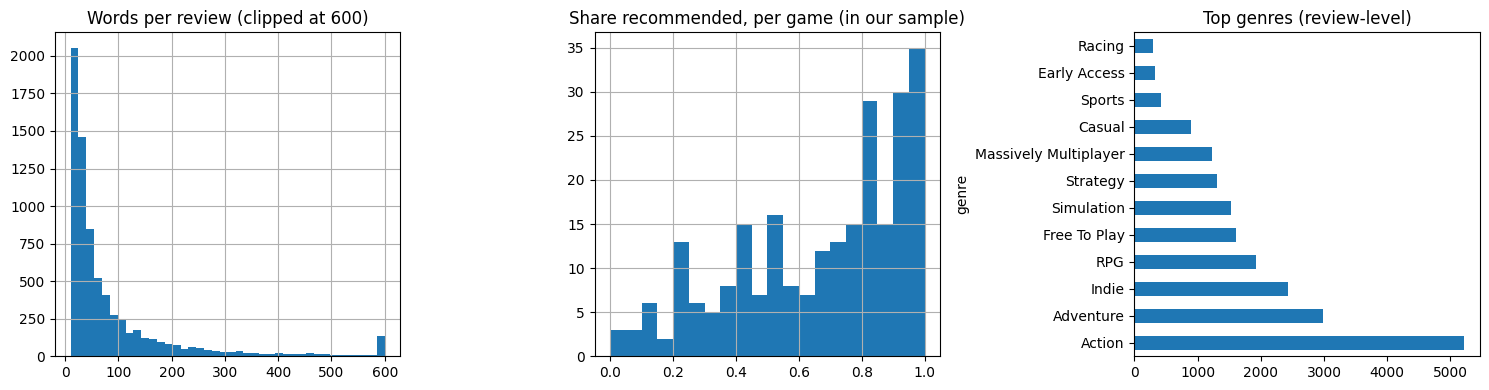

In [ ]:
# Quick descriptive views to support your write-up
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
corpus.n_words.clip(upper=600).hist(bins=40, ax=ax[0]); ax[0].set_title("Words per review (clipped at 600)")
corpus.groupby("app_id").voted_up.mean().hist(bins=20, ax=ax[1]); ax[1].set_title("Share recommended, per game (in our sample)")
(corpus.genre.str.split(", ").explode().value_counts().head(12)
       .plot.barh(ax=ax[2])); ax[2].set_title("Top genres (review-level)")
plt.tight_layout(); plt.show()

In [ ]:
from google.colab import drive
drive.mount('/content/portfolio-drive')

# Task B. Explore the language of the reviews

This section starts from the saved `steam_corpus_clean.csv`, so you it can run  **without re-running the scraper (Part A)**, just needs re uploading output files.

Steps:
1. **Preprocess** each review with spaCy: lowercase, lemmatize ("fights" → "fight"), drop stopwords, numbers and punctuation.
   The lemmatized text is saved and reused in Tasks C–F.
2. **Word frequency**: count in how many *reviews* each word appears (document frequency), separately for nouns and
   adjectives, plus common two-word phrases ("open world", "co op"). Document frequency is used instead of raw counts
   so that one long review repeating "grind" 20 times doesn't dominate.
3. **Attribute dictionary**: group related words into attributes (e.g. story = story, narrative, plot, lore).
4. **Lift analysis**: for each pair of attributes, how much more often are they mentioned together than we'd expect if they were unrelated.

In [ ]:
!python -m spacy download en_core_web_md

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 33.5/33.5 MB 49.2 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_md')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [ ]:
import re, numpy as np, pandas as pd
import spacy, matplotlib.pyplot as plt, seaborn as sns
from collections import Counter
from sklearn.feature_extraction.text import CountVectorizer

corpus = pd.read_csv("steam_corpus_clean.csv")
nlp = spacy.load("en_core_web_md", disable=["parser", "ner"])

# Words that are everywhere in game reviews and carry no attribute information.
# ✍️ Your group can add/remove words here — explain your choices in the write-up.
DOMAIN_STOP = {"game", "play", "playing", "player", "get", "make", "go", "thing", "lot", "time",
               "really", "even", "also", "would", "one", "like", "just", "still", "want",
               "steam", "review", "hour", "buy", "people", "way", "say", "know", "think", "much"}

def preprocess(doc):
    toks = [t for t in doc if t.is_alpha and not t.is_stop and len(t) > 2]
    lemmas = [t.lemma_.lower() for t in toks if t.lemma_.lower() not in DOMAIN_STOP]
    nouns  = [t.lemma_.lower() for t in toks if t.pos_ == "NOUN" and t.lemma_.lower() not in DOMAIN_STOP]
    adjs   = [t.lemma_.lower() for t in toks if t.pos_ == "ADJ"  and t.lemma_.lower() not in DOMAIN_STOP]
    return " ".join(lemmas), nouns, adjs

out = [preprocess(d) for d in nlp.pipe(corpus.review.str.lower(), batch_size=200)]
corpus["lemmas"] = [o[0] for o in out]
corpus["nouns"]  = [o[1] for o in out]
corpus["adjs"]   = [o[2] for o in out]
corpus.drop(columns=["nouns", "adjs"]).to_csv("steam_corpus_processed.csv", index=False)
corpus[["review", "lemmas"]].head(3)

,review,lemmas
0,I originally bought this game back in 2021 to ...,originally cheer friend proceed straight year ...
1,"If you're insulting the founder of a country, ...",insult founder country reason recommend accept...
2,"After the PUBG Asia Stars incident, the way PU...",pubg asia stars incident pubg operate honestly...


### B.1 Word frequency (number of reviews mentioning each word)

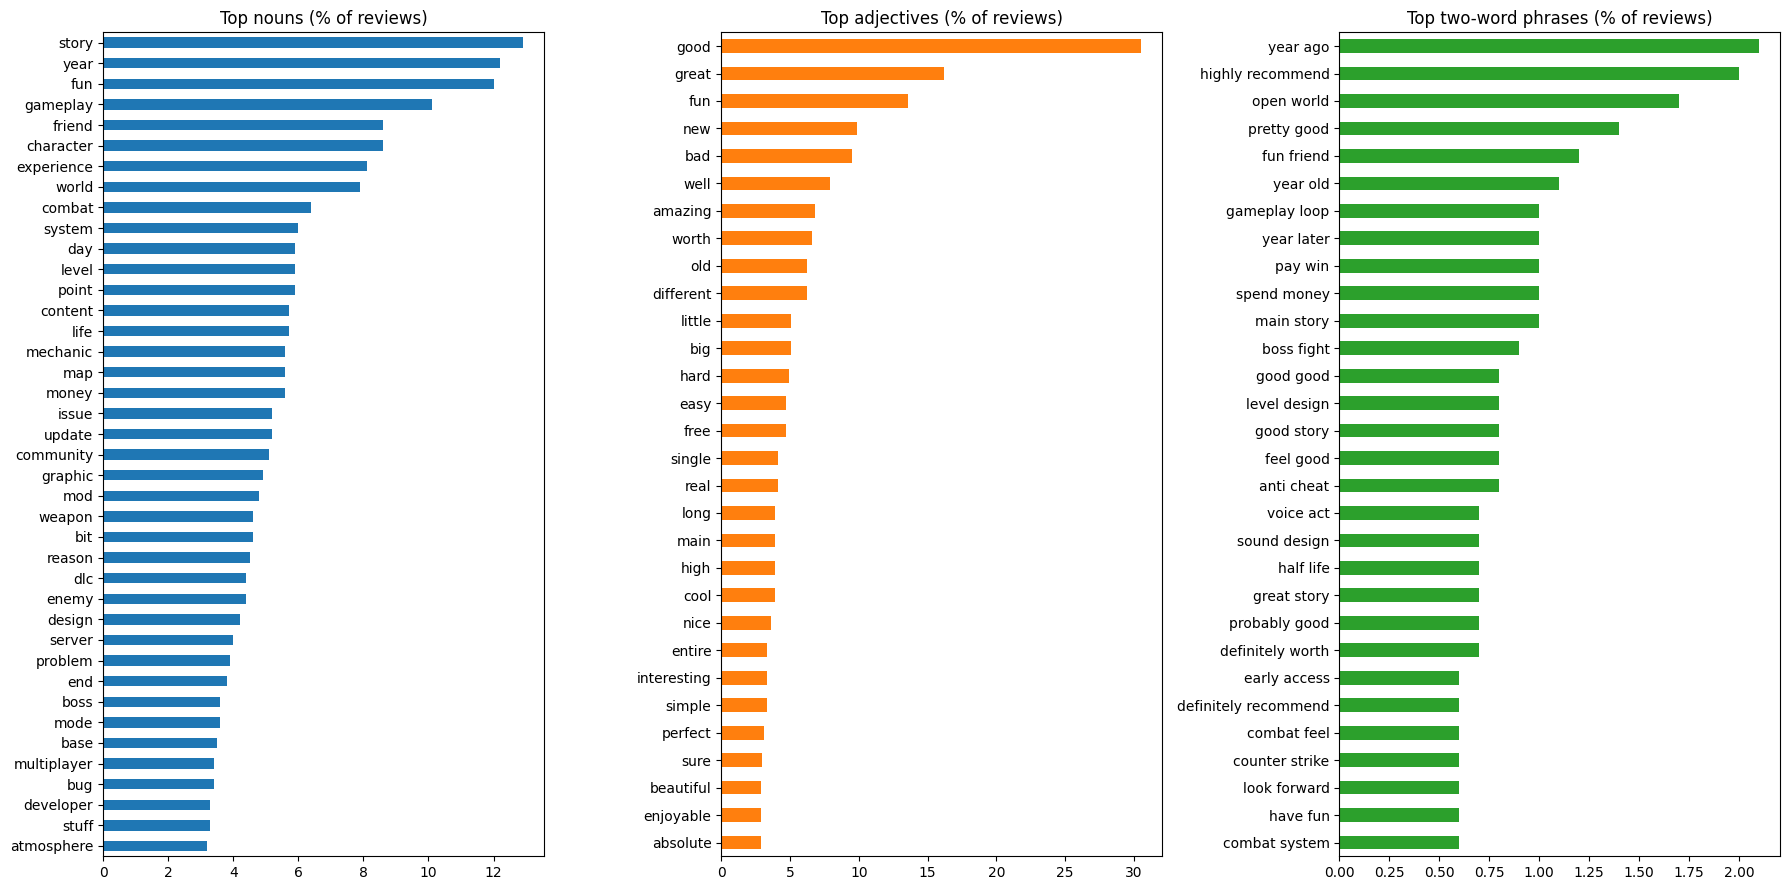

In [ ]:
def doc_freq(list_col, top=40):
    c = Counter()
    for toks in list_col:
        c.update(set(toks))           # set() → count each word once per review
    s = pd.Series(c).sort_values(ascending=False).head(top)
    return (s / len(corpus) * 100).round(1)   # % of reviews

top_nouns = doc_freq(corpus.nouns, 40)
top_adjs  = doc_freq(corpus.adjs, 30)

bigram_vec = CountVectorizer(ngram_range=(2, 2), binary=True, min_df=20)
B = bigram_vec.fit_transform(corpus.lemmas)
top_bigrams = (pd.Series(np.asarray(B.sum(0)).ravel(), index=bigram_vec.get_feature_names_out())
                 .sort_values(ascending=False).head(30) / len(corpus) * 100).round(1)

fig, ax = plt.subplots(1, 3, figsize=(18, 9))
top_nouns[::-1].plot.barh(ax=ax[0], title="Top nouns (% of reviews)")
top_adjs[::-1].plot.barh(ax=ax[1], title="Top adjectives (% of reviews)", color="tab:orange")
top_bigrams[::-1].plot.barh(ax=ax[2], title="Top two-word phrases (% of reviews)", color="tab:green")
plt.tight_layout(); plt.show()

### B.2 Attribute dictionary
Each attribute is a set of regular-expression patterns matched on the lowercased review text
(not the lemmas, so phrases like "co-op" and "open world" survive). A review "mentions" an attribute if any pattern matches.


In [ ]:
ATTRIBUTES = {
    "story":        r"\bstor(y|ies|yline|ytelling)\b|\bnarrative|\bplot\b|\blore\b|\bwriting\b",
    "combat":       r"\bcombat\b|\bfight(s|ing)?\b|\bboss(es)?\b|\bgunplay\b|\bshoot(ing)?\b",
    "exploration":  r"\bexplor(e|ing|ation)\b|\bopen[- ]world\b|\bdiscover(y|ing)?\b",
    "immersion":    r"\bimmers(ive|ion)\b|\batmospher(e|ic)\b|\bworld[- ]?building\b",
    "graphics":     r"\bgraphic(s)?\b|\bvisual(s|ly)?\b|\bart ?style\b|\bbeautiful\b",
    "difficulty":   r"\bdifficult(y)?\b|\bchalleng(e|ing)\b|\bhard\b|\bpunishing\b",
    "multiplayer":  r"\bmultiplayer\b|\bco-?op\b|\bonline\b|\bfriends?\b|\bpvp\b",
    "grind":        r"\bgrind(y|ing)?\b|\brepetitive\b|\btedious\b|\bboring\b",
    "progression":  r"\bprogress(ion)?\b|\blevel(ing|ling)? up\b|\bunlock(s|ing)?\b|\bupgrade(s)?\b",
    "performance":  r"\bperformance\b|\blag(gy|s)?\b|\bfps\b|\bcrash(es|ing)?\b|\boptimi[sz](ed|ation)\b|\bbug(s|gy)?\b",
    "controls":     r"\bcontrol(s|ler)?\b|\bclunky\b|\bresponsive\b",
    "replayability":r"\breplay(ability|able)?\b|\bhours of fun\b",
    "monetization": r"\bmicrotransactions?\b|\bpay[- ]to[- ]win\b|\bloot ?box(es)?\b|\bbattle ?pass\b|\bdlc\b",
    "price":        r"\bprice(d)?\b|\bworth\b|\bmoney\b|\bcheap\b|\bexpensive\b|\bsale\b",
    "developers":   r"\bdev(s|elopers?)\b|\bupdates?\b|\bpatch(es)?\b",
}

import warnings; warnings.filterwarnings("ignore", message="This pattern")
text = corpus.review.str.lower()
M = pd.DataFrame({a: text.str.contains(p, regex=True).astype(int) for a, p in ATTRIBUTES.items()})

# Optional: add the rating as two pseudo-attributes, so lift also shows which attributes
# are over-represented in Recommended vs. Not Recommended reviews
M["RECOMMENDED"]     = corpus.voted_up
M["NOT_RECOMMENDED"] = 1 - corpus.voted_up

mention_rate = (M.mean() * 100).round(1).sort_values(ascending=False)
games_mentioning = pd.Series({a: corpus.loc[M[a] == 1, "app_id"].nunique() for a in ATTRIBUTES})
pd.DataFrame({"% of reviews": mention_rate, "# games with ≥1 mention": games_mentioning}).dropna()

,% of reviews,# games with ≥1 mention
combat,13.6,199.0
controls,4.0,152.0
developers,11.8,210.0
difficulty,10.4,221.0
exploration,5.8,132.0
graphics,10.1,207.0
grind,7.8,182.0
immersion,4.6,122.0
monetization,6.1,141.0
multiplayer,15.3,214.0


Reviewers talk most about story, multiplayer, price, and combat, and the attributes in our request (immersion, story, exploration) are strongly co-mentioned, so the request is realistic for this corpus.

### Frequency

The most common words are generic praise (`good` 31% of reviews, `fun` 24%, `great` 16%), which carries no attribute information. Among attribute words, `story` appears in 13% of reviews, `world` in 8%, and `character` in 9%. Frequent two-word phrases include `open world`, `main story`, `boss fight`, `gameplay loop`, `level design`, and `pay win` (pay-to-win).

Grouping words into attributes gives these mention rates ranked by%:

| Attribute | % of reviews | Games with ≥1 mention |
|---|---:|---:|
| story | 16.2% | 195 |
| multiplayer | 15.3% | 214 |
| price | 14.5% | 232 |
| combat | 13.6% | 199 |
| developers / updates | 11.8% | 210 |
| performance | 11.0% | 208 |
| difficulty | 10.4% | 221 |
| graphics | 10.1% | 207 |
| grind | 7.8% | 182 |
| progression | 6.9% | 173 |
| monetization | 6.1% | 141 |
| exploration | 5.8% | 132 |
| immersion | 4.6% | 122 |
| controls | 4.0% | 152 |
| replayability | 2.4% | 108 |

### B.3 Lift analysis
For attributes A and B:

$$\text{lift}(A,B) = \frac{P(A \cap B)}{P(A)\,P(B)} = \frac{N \cdot n_{AB}}{n_A \cdot n_B}$$

- lift > 1: mentioned together **more** often than chance
- lift ≈ 1: unrelated
- lift < 1: mentioned together **less** often than chance

Pairs with very few co-mentions give unstable lifts, so the table below also shows the raw co-mention count.

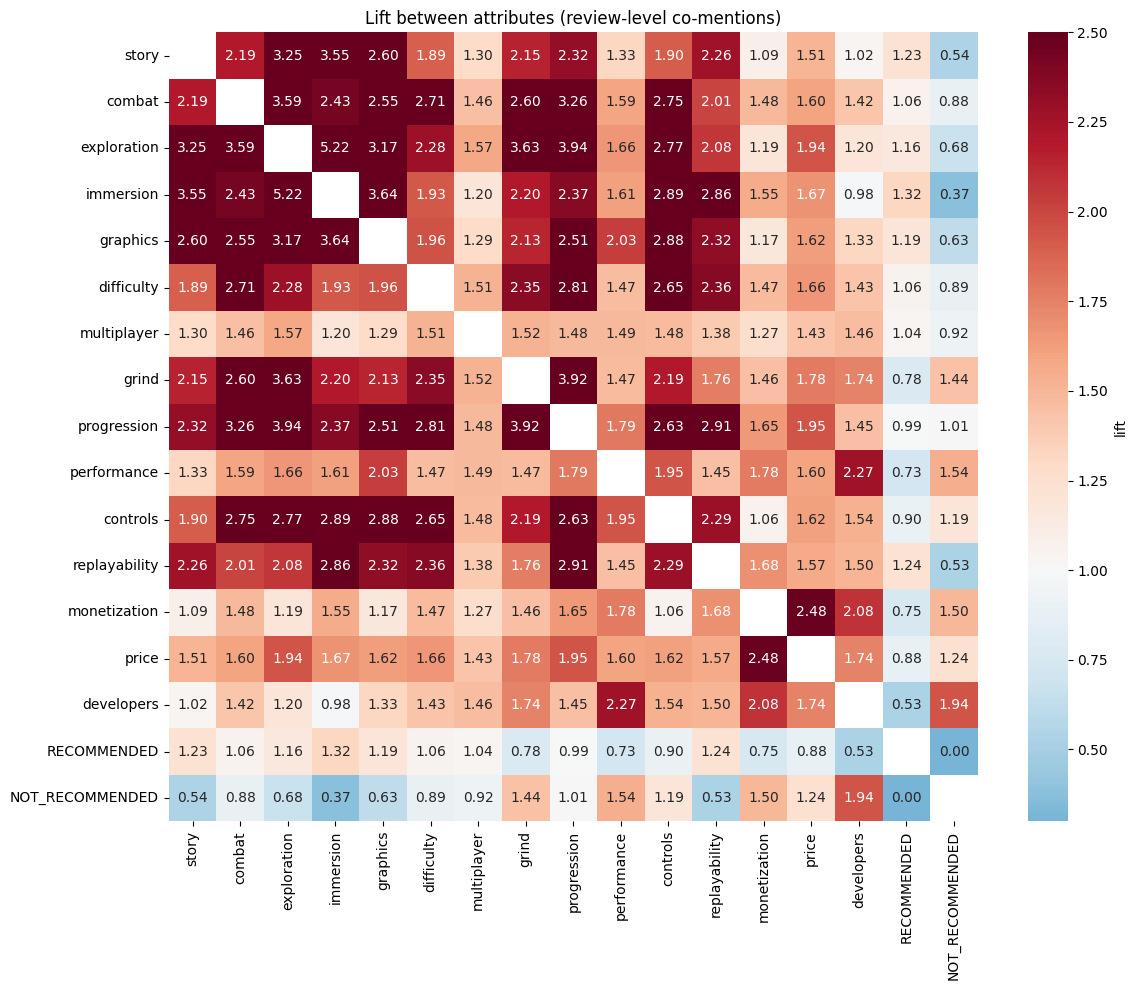

In [ ]:
N = len(M)
cols = list(M.columns)
co = M.T.dot(M)                                  # co-mention counts
n = np.diag(co)
with np.errstate(divide="ignore", invalid="ignore"):
    L = N * co.values / np.outer(n, n)
np.fill_diagonal(L, np.nan)
lift = pd.DataFrame(L, index=cols, columns=cols)

plt.figure(figsize=(12, 10))
sns.heatmap(lift, annot=True, fmt=".2f", cmap="RdBu_r", center=1, vmin=0.3, vmax=2.5, cbar_kws={"label": "lift"})
plt.title("Lift between attributes (review-level co-mentions)")
plt.tight_layout(); plt.show()

In [ ]:
MIN_CO = 30   # ignore pairs mentioned together fewer than this many times

pairs = []
for i, a in enumerate(cols):
    for b in cols[i + 1:]:
        if {a, b} == {"RECOMMENDED", "NOT_RECOMMENDED"}:
            continue
        pairs.append({"A": a, "B": b, "n_A": n[i], "n_B": n[cols.index(b)],
                      "co_mentions": co.loc[a, b], "lift": lift.loc[a, b]})
pairs = pd.DataFrame(pairs)
pairs = pairs[pairs.co_mentions >= MIN_CO].sort_values("lift", ascending=False)

print("Highest-lift pairs:");  display(pairs.head(12).round(2))
print("Lowest-lift pairs:");   display(pairs.tail(8).round(2))

Highest-lift pairs:


,A,B,n_A,n_B,co_mentions,lift
31,exploration,immersion,425,338,102,5.22
36,exploration,progression,425,505,115,3.94
91,grind,progression,572,505,154,3.92
45,immersion,graphics,338,741,124,3.64
35,exploration,grind,425,572,120,3.63
16,combat,exploration,1003,425,208,3.59
2,story,immersion,1187,338,194,3.55
22,combat,progression,1003,505,225,3.26
1,story,exploration,1187,425,223,3.25
32,exploration,graphics,425,741,136,3.17


Lowest-lift pairs:


,A,B,n_A,n_B,co_mentions,lift
128,monetization,RECOMMENDED,449,4890,224,0.75
113,performance,RECOMMENDED,811,4890,393,0.73
44,exploration,NOT_RECOMMENDED,425,2459,96,0.68
69,graphics,NOT_RECOMMENDED,741,2459,155,0.63
15,story,NOT_RECOMMENDED,1187,2459,213,0.54
125,replayability,NOT_RECOMMENDED,175,2459,31,0.53
133,developers,RECOMMENDED,865,4890,304,0.53
57,immersion,NOT_RECOMMENDED,338,2459,42,0.37


In [ ]:
# ✍️ Put the attributes from YOUR user request here, to check whether they
# actually appear together in the review data.
REQUEST_ATTRIBUTES = ["immersion", "story", "exploration", "combat", "difficulty", "grind"]

sub = lift.loc[REQUEST_ATTRIBUTES, REQUEST_ATTRIBUTES + ["RECOMMENDED", "NOT_RECOMMENDED"]]
display(sub.round(2))

# How many games have reviews mentioning ALL the positive attributes of the request?
POSITIVE = ["immersion", "story", "exploration"]    # ✍️ edit
game_cov = M[POSITIVE].groupby(corpus.app_id).max()
print(f"Games whose reviews mention all of {POSITIVE}: {int((game_cov.sum(1) == len(POSITIVE)).sum())} of {corpus.app_id.nunique()}")

,immersion,story,exploration,combat,difficulty,grind,RECOMMENDED,NOT_RECOMMENDED
immersion,NaN,3.55,5.22,2.43,1.93,2.20,1.32,0.37
story,3.55,NaN,3.25,2.19,1.89,2.15,1.23,0.54
exploration,5.22,3.25,NaN,3.59,2.28,3.63,1.16,0.68
combat,2.43,2.19,3.59,NaN,2.71,2.60,1.06,0.88
difficulty,1.93,1.89,2.28,2.71,NaN,2.35,1.06,0.89
grind,2.20,2.15,3.63,2.60,2.35,NaN,0.78,1.44


Games whose reviews mention all of ['immersion', 'story', 'exploration']: 79 of 248


### Lift

The strongest pairs are **exploration–immersion (5.2, 102 co-mentions)**, **exploration–progression (3.9)**, **grind–progression (3.9)**, and **story–immersion (3.6)**.

Every attribute in our request co-occurs well above chance (lift 1.9–5.2), and **79 of 248 games** have reviews mentioning immersion, story, and exploration.

Pairing attributes with the rating shows which ones signal satisfaction: **immersion (1.32 with Recommended vs. 0.37 with Not Recommended), story (1.23 vs. 0.54), and exploration (1.16 vs. 0.68)** lean positive, while **grind** leans negative (0.78 vs. 1.44).

### What this means for the recommender

- **Our request is supported by the data:** the attributes we ask for appear together in real reviews.
- **Grind is mostly mentioned as a complaint**, so a review mentioning grind is evidence against a game for this user. A BoW query that contains `"grindy"` rewards exactly the wrong reviews.
- **Grind also co-occurs with exploration (3.6) and combat (2.6)**, so open-world games will match our positive terms and the term we want to avoid at the same time.
- **Exploration and immersion are rare** (6% and 5% of reviews), so a few reviews per game carry those signals. That is why we score games on their most relevant reviews rather than averaging all 30.

### Measurement caveats

Some patterns are noisy: `"hard"` also matches `"hard drive"`, `"fps"` also matches the shooter genre, `"friends"` does not always mean multiplayer, and `"boring"` is counted as grind. Preprocessing drops two-letter tokens, so `"co-op"` disappears from the lemmas.

#Task C.  Recommender 1 — Bag-of-Words + cosine similarity

BoW recommends The Witcher 3 (score 0.290), Red Dead Redemption 2 (0.258) and Assassin's Creed Odyssey (0.253): all story-driven open-world games, which fits the request. Its main weakness is negation.
Method in plain English.
1. Preprocess. The request and every review go through the same spaCy pipeline: lowercase, lemmatize ("fights" → "fight"), and drop stopwords, numbers, words of two letters or fewer, and domain stopwords like "game" and "play". The request becomes 13 words: deep immersive story big world explore enjoy challenge satisfy combat feel repetitive grindy.
2. Represent. We count words in each review over a 6,798-word vocabulary (words appearing in at least 3 reviews). The request is treated as one more document; all 13 of its words are in the vocabulary.
3. Similarity. Cosine similarity between the request vector and each review vector measures word overlap, adjusted for review length.
4. Sentiment. VADER gives each review a compound score from −1 to +1. It separates the two groups well: 0.574 on average for Recommended reviews vs. −0.022 for Not Recommended.
5. Combine. We rescale sentiment to a 0–1 weight, (1 + compound) / 2, and multiply: review score = similarity × weight. A review that matches the request but is negative gets pulled toward zero.
6. Aggregate. A game's score is the average of its 5 highest review scores. We use the top 5 rather than all 30 because most reviews never mention the requested attributes (exploration and immersion appear in only 5–6% of reviews), so averaging all 30 would mostly measure how often a game's reviews happen to discuss them.

## C.1 Setup, preprocess the query

In [ ]:
import re, numpy as np, pandas as pd
import spacy
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.metrics.pairwise import cosine_similarity
import nltk
nltk.download("vader_lexicon", quiet=True)
from nltk.sentiment import SentimentIntensityAnalyzer

corpus = pd.read_csv("steam_corpus_processed.csv")
nlp = spacy.load("en_core_web_md", disable=["parser", "ner"])
sia = SentimentIntensityAnalyzer()

# Same domain stopword list as Task B, so the query is preprocessed exactly
# the way the reviews were — otherwise the two vectors wouldn't be comparable.
DOMAIN_STOP = {"game", "play", "playing", "player", "get", "make", "go", "thing", "lot", "time",
               "really", "even", "also", "would", "one", "like", "just", "still", "want",
               "steam", "review", "hour", "buy", "people", "way", "say", "know", "think", "much"}

def preprocess_query(text):
    doc = nlp(text.lower())
    toks = [t for t in doc if t.is_alpha and not t.is_stop and len(t) > 2]
    lemmas = [t.lemma_.lower() for t in toks if t.lemma_.lower() not in DOMAIN_STOP]
    return " ".join(lemmas)

# ✍️ Replace with your group's actual request (same one used in Tasks B and D–F).
USER_REQUEST = ("I want a game with a deep, immersive story and a big world to explore. I enjoy challenging, satisfying combat, but I don't want something that feels repetitive or grindy.")

query_lemmas = preprocess_query(USER_REQUEST)
print("Query lemmas:", query_lemmas)

Query lemmas: deep immersive story big world explore enjoy challenge satisfy combat feel repetitive grindy


We preprocessed the group's request with the same pipeline used on the reviews (lowercasing, spaCy lemmatization, domain stopword removal), producing the lemma string deep immersive story big world explore enjoy challenge satisfy combat feel repetitive grindy. The positive attributes, story, immersion, exploration, combat, came through cleanly. One limitation surfaced here: negation is lost. "Don't want anything grindy" drops don't/want as stopwords, leaving grindy and repetitive in the query with no signal they should be avoided rather than sought. This is inherent to bag-of-words, not a bug in our pipeline, and we carry it forward as a known caveat for this recommender.

## C.2 Build BoW vectors, cosine similarity

In [ ]:
# Vocabulary is fit on the review corpus only. A query word that never appears
# in any review can't match anything anyway, so it's fine to leave it out.
vectorizer = CountVectorizer(min_df=3)   # drop ultra-rare tokens (typos/noise)
X = vectorizer.fit_transform(corpus.lemmas.fillna(""))   # (n_reviews x vocab)
q = vectorizer.transform([query_lemmas])                  # (1 x vocab)

print("Vocabulary size:", len(vectorizer.vocabulary_))
in_vocab = [w for w in query_lemmas.split() if w in vectorizer.vocabulary_]
print(f"Query words found in review vocabulary ({len(in_vocab)}/{len(query_lemmas.split())}):", in_vocab)

corpus["similarity"] = cosine_similarity(q, X).ravel()
corpus[["name", "review", "similarity"]].sort_values("similarity", ascending=False).head(10)

Vocabulary size: 6798
Query words found in review vocabulary (13/13): ['deep', 'immersive', 'story', 'big', 'world', 'explore', 'enjoy', 'challenge', 'satisfy', 'combat', 'feel', 'repetitive', 'grindy']


,name,review,similarity
2153,Assassin's Creed Odyssey,I absolutely loved Assassin’s Creed Odyssey. T...,0.421199
376,Hogwarts Legacy,Great game with such a beautiful world to expl...,0.367279
2880,The Witcher 3: Wild Hunt - Complete Edition,The Witcher 3 is the best game made ever The W...,0.357298
479,The Witcher 3: Wild Hunt - Complete Edition,THE BEST GAME EVER The Witcher 3: Wild Hunt is...,0.355151
1718,Fallout 4,Fallout 4 Review Overview Fallout 4 is a weird...,0.320367
3977,Divinity: Original Sin 2 - Definitive Edition,The game is finally click for me after I stopp...,0.318142
2075,God of War,I really enjoyed this game from beginning to e...,0.302736
244,Starfield,Starfield Review Overview I have never been a ...,0.300918
2348,Red Dead Redemption 2,There is not much to say about this game besid...,0.298881
6131,Life is Strange 2,I enjoyed it less than it's predecessor but i ...,0.296500


With `min_df=3`, the review corpus produced a vocabulary of 6,804 terms, and all 13 words from the query lemma string were found in it, no vocabulary mismatch to worry about. Cosine similarity against this space surfaces a sensible top 10: story-and-exploration-heavy open-world titles (Assassin's Creed Odyssey, Hogwarts Legacy, The Witcher 3, Shadow of Mordor, Fallout 4, Divinity: Original Sin 2, God of War, Starfield) dominate, which lines up well with the request. Assassin's Creed Odyssey appears twice from two different reviewers, both scoring highly, which is a good early sign that the match isn't a fluke of one unusual review.

## C.3 Sentiment (VADER)

In [ ]:
corpus["sentiment"] = corpus.review.apply(lambda t: sia.polarity_scores(str(t))["compound"])

print("Mean sentiment, Recommended reviews:    ", corpus.loc[corpus.voted_up == 1, "sentiment"].mean().round(3))
print("Mean sentiment, Not Recommended reviews:", corpus.loc[corpus.voted_up == 0, "sentiment"].mean().round(3))

corpus[["name", "review", "voted_up", "sentiment"]].sort_values("sentiment").head(5)

Mean sentiment, Recommended reviews:     0.572
Mean sentiment, Not Recommended reviews: -0.023


,name,review,voted_up,sentiment
2397,Resident Evil Village,Resident Evil Village - An Overwhelmingly Medi...,0,-0.9996
1256,Hades II,I really want to give this game a positive rev...,0,-0.9994
1630,Tomb Raider Game of the Year,【ENGLISH VERSION】 This is where my dream start...,1,-0.9992
1923,Path of Exile,"Title: A Masterclass in Isometric Malice, Grin...",0,-0.9989
1042,Path of Exile 2,"Title: A Masterclass in Isometric Malice, Grin...",0,-0.9989


VADER validates well overall: "Recommended" reviews average 0.572 sentiment vs. -0.02 for "Not Recommended," sensible, since critical reviews are often measured rather than harshly negative. The five most negative reviews mostly line up with "Not Recommended" (Resident Evil Village, Path of Exile ×2, Warhammer 40K: Space Marine 2). One exception: the Tomb Raider GOTY review scores -0.999 despite being voted_up = 1, likely dark/intense vocabulary being read as negative even when praising the game. We'll flag this as a known limitation going into C.4, where it could wrongly suppress a good match's score.

## C.4 Combine similarity + sentiment into a review-level score

In [ ]:
# Map VADER's [-1, 1] compound score to a [0, 1] multiplier. A neutral-to-positive
# review keeps most/all of its similarity score; a strongly negative review gets
# pulled toward 0 even if its language matches the request closely — this is what
# stops similarity alone from driving the recommendation.
corpus["sentiment_weight"] = (1 + corpus.sentiment) / 2
corpus["relevance_score"] = corpus.similarity * corpus.sentiment_weight

corpus.sort_values("relevance_score", ascending=False)[
    ["name", "review", "similarity", "sentiment", "relevance_score"]].head(10)

,name,review,similarity,sentiment,relevance_score
2153,Assassin's Creed Odyssey,I absolutely loved Assassin’s Creed Odyssey. T...,0.421199,0.9728,0.415470
376,Hogwarts Legacy,Great game with such a beautiful world to expl...,0.367279,0.9935,0.366086
2880,The Witcher 3: Wild Hunt - Complete Edition,The Witcher 3 is the best game made ever The W...,0.357298,0.9994,0.357191
479,The Witcher 3: Wild Hunt - Complete Edition,THE BEST GAME EVER The Witcher 3: Wild Hunt is...,0.355151,0.9992,0.355009
1718,Fallout 4,Fallout 4 Review Overview Fallout 4 is a weird...,0.320367,0.9896,0.318701
2075,God of War,I really enjoyed this game from beginning to e...,0.302736,0.9993,0.302630
244,Starfield,Starfield Review Overview I have never been a ...,0.300918,0.9992,0.300798
2019,The Witcher 3: Wild Hunt - Complete Edition,Even after playing through the first two games...,0.295697,0.9954,0.295017
7062,The Witcher 2: Assassins of Kings Enhanced Edi...,★★★★☆ ✦ 𝟒/𝟓 ✦ A massive step forward and the f...,0.293211,0.9937,0.292288
4055,Metro 2033 Redux,Metro 2033 is one of those games that stays wi...,0.291848,0.9904,0.290447


Because the most similar reviews were already strongly positive (sentiment mostly 0.90–0.999), the sentiment weight stayed close to 1, so `relevance_score` barely differs from raw `similarity` for this top-10, order is essentially unchanged from C.2. That's expected and reassuring: it confirms the highest-similarity reviews aren't being penalized for language that only *sounds* negative. The sentiment step should matter more further down the ranking, where similarity is decent but tone is mixed, that's where multiplying by sentiment will actually reorder things rather than just confirm them.

## C.5 Aggregate to the game level

In [ ]:
TOP_N = 5   # average each game's N most relevant reviews, not all of them

def aggregate_game(g):
    top = g.sort_values("relevance_score", ascending=False).head(TOP_N)
    return pd.Series({
        "n_reviews_in_corpus":  len(g),
        "n_reviews_used":       len(top),
        "avg_similarity":       top.similarity.mean(),
        "avg_sentiment":        top.sentiment.mean(),
        "score":                top.relevance_score.mean(),
        "pct_positive_overall": g.pct_positive.iloc[0],
        "top_tags":             g.top_tags.iloc[0],
    })

game_scores = (corpus.groupby(["app_id", "name"])
                     .apply(aggregate_game)
                     .reset_index()
                     .sort_values("score", ascending=False))
game_scores.head(10).round(3)

<notebook>/3409721392.py:16: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(aggregate_game)


,app_id,name,n_reviews_in_corpus,n_reviews_used,avg_similarity,avg_sentiment,score,pct_positive_overall,top_tags
93,292030,The Witcher 3: Wild Hunt - Complete Edition,30,5,0.291,0.994,0.290,0.968,"Open World, RPG, Story Rich, Atmospheric, Matu..."
198,1174180,Red Dead Redemption 2,30,5,0.263,0.967,0.258,0.920,"Open World, Story Rich, Western, Adventure, Mu..."
171,812140,Assassin's Creed Odyssey,30,5,0.258,0.954,0.253,0.893,"Open World, RPG, Singleplayer, Historical, Act..."
184,990080,Hogwarts Legacy,30,5,0.255,0.885,0.240,0.910,"Magic, Open World, Fantasy, Singleplayer, Adve..."
240,2358720,Black Myth: Wukong,30,5,0.230,0.971,0.227,0.938,"Mythology, Action RPG, Action, Souls-like, RPG..."
189,1091500,Cyberpunk 2077,30,5,0.226,0.969,0.223,0.890,"Cyberpunk, Open World, Nudity, RPG, Singleplay..."
81,271590,Grand Theft Auto V Legacy,30,5,0.225,0.975,0.222,0.837,"Open World, Action, Multiplayer, Crime, Automo..."
25,20920,The Witcher 2: Assassins of Kings Enhanced Edi...,30,5,0.223,0.964,0.219,0.882,"RPG, Fantasy, Mature, Story Rich, Choices Matt..."
90,286690,Metro 2033 Redux,30,5,0.213,0.979,0.211,0.890,"Post-apocalyptic, FPS, Atmospheric, Story Rich..."
195,1172380,STAR WARS Jedi: Fallen Order,30,5,0.214,0.967,0.211,0.890,"Action-Adventure, Souls-like, Third Person, Op..."


The top-5-per-game aggregation gives a coherent, genre-consistent leaderboard: The Witcher 3 leads (0.290), followed by Red Dead Redemption 2 (0.258), Assassin's Creed Odyssey (0.253) and Hogwarts Legacy (0.240), all open-world, story-rich, exploration-heavy titles that match the request. Sentiment is high for most top games (0.95–0.99), so `score` mostly tracks `avg_similarity`, but it does reorder one key spot: Hogwarts Legacy has almost the same similarity as AC Odyssey (0.255 vs. 0.258) but lower sentiment (0.885 vs. 0.954), which drops it from #3 to #4. Its lower sentiment comes from reviews that praise the world but complain that the game is repetitive. That is the real negation problem from C.1: because "repetitive" and "grindy" are in the query, reviews that

## C.6 Final table + the 3 recommendations

In [ ]:
TOP_K = 25   # 3 recommendations + at least 20 other contenders

results = game_scores.head(TOP_K).reset_index(drop=True)
results.index = results.index + 1
display(results.rename_axis("rank").round(3))

print("\nTop 3 recommendations:")
for _, row in game_scores.head(3).iterrows():
    print(f"  • {row['name']}  (score={row.score:.3f}, avg similarity={row.avg_similarity:.3f}, avg sentiment={row.avg_sentiment:.3f})")

,app_id,name,n_reviews_in_corpus,n_reviews_used,avg_similarity,avg_sentiment,score,pct_positive_overall,top_tags
rank,,,,,,,,,
1,292030,The Witcher 3: Wild Hunt - Complete Edition,30,5,0.291,0.994,0.290,0.968,"Open World, RPG, Story Rich, Atmospheric, Matu..."
2,1174180,Red Dead Redemption 2,30,5,0.263,0.967,0.258,0.920,"Open World, Story Rich, Western, Adventure, Mu..."
3,812140,Assassin's Creed Odyssey,30,5,0.258,0.954,0.253,0.893,"Open World, RPG, Singleplayer, Historical, Act..."
4,990080,Hogwarts Legacy,30,5,0.255,0.885,0.240,0.910,"Magic, Open World, Fantasy, Singleplayer, Adve..."
5,2358720,Black Myth: Wukong,30,5,0.230,0.971,0.227,0.938,"Mythology, Action RPG, Action, Souls-like, RPG..."
6,1091500,Cyberpunk 2077,30,5,0.226,0.969,0.223,0.890,"Cyberpunk, Open World, Nudity, RPG, Singleplay..."
7,271590,Grand Theft Auto V Legacy,30,5,0.225,0.975,0.222,0.837,"Open World, Action, Multiplayer, Crime, Automo..."
8,20920,The Witcher 2: Assassins of Kings Enhanced Edi...,30,5,0.223,0.964,0.219,0.882,"RPG, Fantasy, Mature, Story Rich, Choices Matt..."
9,286690,Metro 2033 Redux,30,5,0.213,0.979,0.211,0.890,"Post-apocalyptic, FPS, Atmospheric, Story Rich..."



Top 3 recommendations:
  • The Witcher 3: Wild Hunt - Complete Edition  (score=0.290, avg similarity=0.291, avg sentiment=0.994)
  • Red Dead Redemption 2  (score=0.258, avg similarity=0.263, avg sentiment=0.967)
  • Assassin's Creed Odyssey  (score=0.253, avg similarity=0.258, avg sentiment=0.954)


The final table shows a genre-coherent ranking: scores decline from 0.290 to 0.171 across 25 titles, almost all open-world, story-rich or exploration-heavy games. The Witcher 3 is a clear first (0.290, 0.032 ahead of #2), while Red Dead Redemption 2 (0.258) and Assassin's Creed Odyssey (0.253) sit close to Hogwarts Legacy (0.240) and Black Myth: Wukong (0.227), so places #2–#5 could swap with small changes in the data. Souls-like games such as Black Myth: Wukong (#5) and Sekiro (#18) are a reasonable result, since the user asked for challenging combat. The real weakness is negation: "repetitive" and "grindy" count as

### Results

The top 25 runs range from **0.290 down to 0.171**, and the top three sit close together. **Assassin's Creed Odyssey** beats **Hogwarts Legacy** for #3 (0.253 vs. 0.240) on sentiment, not similarity: their similarity scores are nearly tied (0.258 vs. 0.255), but Hogwarts' five best-matching reviews average **0.885 sentiment** vs. **0.954** for Assassin's Creed Odyssey. On similarity alone, Hogwarts would rank #3.

One of those five reviews calls the game **"incredibly boring and repetitive,"** yet VADER still scores it **+0.50** because of words like `"great"` and `"beautiful"`.

### Where BoW Fails: Negation

BoW reads **"I don't want something that feels repetitive or grindy"** as a request *for* repetitive and grindy games. Among the 100 reviews most similar to the request, **30% mention grind, repetition, or tedium**, compared with **5.8% of all reviews**.

**Hogwarts Legacy** illustrates the problem well: **3 of its 5 best-matching reviews mention grind or repetition**. Sentiment only partly corrects this because a review can be positive overall while still complaining about the grind.

Games tagged **"Difficult"** or **"Souls-like"** (**Black Myth: Wukong #5, Sekiro #18**) are *not* a failure: the user explicitly asked for challenging combat.

# Task D. Recommender 2 — Pretrained word vectors

## D.1 Setup, preprocess the query

In [ ]:
!python -m spacy download en_core_web_md -q

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 33.5/33.5 MB 53.0 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_md')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [ ]:
import re, numpy as np, pandas as pd
import spacy
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.metrics.pairwise import cosine_similarity
import nltk
nltk.download("vader_lexicon", quiet=True)
from nltk.sentiment import SentimentIntensityAnalyzer

corpus = pd.read_csv("steam_corpus_processed.csv")
nlp = spacy.load("en_core_web_md", disable=["parser", "ner"])
sia = SentimentIntensityAnalyzer()

# Same domain stopword list as Task B, so the query is preprocessed exactly
# the way the reviews were — otherwise the two vectors wouldn't be comparable.
DOMAIN_STOP = {"game", "play", "playing", "player", "get", "make", "go", "thing", "lot", "time",
               "really", "even", "also", "would", "one", "like", "just", "still", "want",
               "steam", "review", "hour", "buy", "people", "way", "say", "know", "think", "much"}

def preprocess_query(text):
    doc = nlp(text.lower())
    toks = [t for t in doc if t.is_alpha and not t.is_stop and len(t) > 2]
    lemmas = [t.lemma_.lower() for t in toks if t.lemma_.lower() not in DOMAIN_STOP]
    return " ".join(lemmas)

# ✍️ Replace with your group's actual request (same one used in Tasks B and D–F).
USER_REQUEST = ("I want a game with a deep, immersive story and a big world to explore. I enjoy challenging, satisfying combat, but I don't want something that feels repetitive or grindy.")

query_lemmas = preprocess_query(USER_REQUEST)
print("Query lemmas:", query_lemmas)

Query lemmas: deep immersive story big world explore enjoy challenge satisfy combat feel repetitive grindy


## D.2 Build pretrained vectors

In [ ]:
# Vocabulary is fit on the review corpus only. A query word that never appears
# in any review can't match anything anyway, so it's fine to leave it out.
#vectorizer = CountVectorizer(min_df=3)   # drop ultra-rare tokens (typos/noise)
#X = vectorizer.fit_transform(corpus.lemmas.fillna(""))   # (n_reviews x vocab)
#q = vectorizer.transform([query_lemmas])                  # (1 x vocab)


X=np.vstack([d.vector for d in nlp.pipe(corpus.lemmas.fillna(''))])
query=nlp(query_lemmas)
q=nlp(query_lemmas).vector.reshape(1,-1)
in_vocab = [w.text for w in query if w.has_vector ]
print(f"Query words found in review vocabulary ({len(in_vocab)}/{len(query_lemmas.split())}):", in_vocab)

corpus["similarity"] = cosine_similarity(q, X).ravel()
corpus[["name", "review", "similarity"]].sort_values("similarity", ascending=False).head(10)

Query words found in review vocabulary (13/13): ['deep', 'immersive', 'story', 'big', 'world', 'explore', 'enjoy', 'challenge', 'satisfy', 'combat', 'feel', 'repetitive', 'grindy']


,name,review,similarity
3834,Satisfactory,"Amazing game and experience, the ending was a ...",0.921666
1932,DARK SOULS III,Dark Souls III is not merely another entry in ...,0.915196
4275,Hollow Knight,A masterpiece of the metroidvania genre. Its w...,0.914104
2216,Mount & Blade II: Bannerlord,Mount & Blade II: Bannerlord is a great mediev...,0.913660
4056,Metro 2033 Redux,I really enjoyed my journey through the Moscow...,0.913069
3237,Hollow Knight,Hollow Knight Review Rating: 9.5/10 Hollow Kni...,0.912850
6309,Half-Life 2,Half-Life 2 is one of the greatest video games...,0.909155
751,Resident Evil Village,"I had heard this game was really good, and was...",0.908492
7285,INSIDE,One of those games you put on during a rainy n...,0.907952
1173,Sekiro: Shadows Die Twice - GOTY Edition,Sekiro was the first FromSoftware title i ever...,0.907853


## D.3 Sentiment (VADER)

In [ ]:
corpus["sentiment"] = corpus.review.apply(lambda t: sia.polarity_scores(str(t))["compound"])

print("Mean sentiment, Recommended reviews:    ", corpus.loc[corpus.voted_up == 1, "sentiment"].mean().round(3))
print("Mean sentiment, Not Recommended reviews:", corpus.loc[corpus.voted_up == 0, "sentiment"].mean().round(3))

corpus[["name", "review", "voted_up", "sentiment"]].sort_values("sentiment").head(5)

Mean sentiment, Recommended reviews:     0.572
Mean sentiment, Not Recommended reviews: -0.023


,name,review,voted_up,sentiment
2397,Resident Evil Village,Resident Evil Village - An Overwhelmingly Medi...,0,-0.9996
1256,Hades II,I really want to give this game a positive rev...,0,-0.9994
1630,Tomb Raider Game of the Year,【ENGLISH VERSION】 This is where my dream start...,1,-0.9992
1923,Path of Exile,"Title: A Masterclass in Isometric Malice, Grin...",0,-0.9989
1042,Path of Exile 2,"Title: A Masterclass in Isometric Malice, Grin...",0,-0.9989


## D.4 Combine similarity + sentiment into a review-level score

In [ ]:
# Map VADER's [-1, 1] compound score to a [0, 1] multiplier. A neutral-to-positive
# review keeps most/all of its similarity score; a strongly negative review gets
# pulled toward 0 even if its language matches the request closely — this is what
# stops similarity alone from driving the recommendation.
corpus["sentiment_weight"] = (1 + corpus.sentiment) / 2
corpus["relevance_score"] = corpus.similarity * corpus.sentiment_weight

corpus.sort_values("relevance_score", ascending=False)[
    ["name", "review", "similarity", "sentiment", "relevance_score"]].head(10)

,name,review,similarity,sentiment,relevance_score
3237,Hollow Knight,Hollow Knight Review Rating: 9.5/10 Hollow Kni...,0.912850,0.9949,0.910522
4056,Metro 2033 Redux,I really enjoyed my journey through the Moscow...,0.913069,0.9851,0.906267
438,Valheim,Valheim is easily the best game I have ever pl...,0.905068,0.9963,0.903393
6870,NARAKA: BLADEPOINT,"⭐ Option 1 — Bold, energetic, hype-filled revi...",0.903747,0.9981,0.902888
2237,Cyberpunk 2077,I had never written a game review before becau...,0.902784,0.9983,0.902017
7062,The Witcher 2: Assassins of Kings Enhanced Edi...,★★★★☆ ✦ 𝟒/𝟓 ✦ A massive step forward and the f...,0.902591,0.9937,0.899748
516,"Warhammer 40,000: Rogue Trader","Abelard, publish my recommendation for this ga...",0.900495,0.9961,0.898740
575,The Elder Scrolls V: Skyrim Special Edition,There is a reason Skyrim has remained in the t...,0.902818,0.9909,0.898710
2189,STAR WARS Jedi: Fallen Order,The Force Is Strong With This Metroidvania STA...,0.899971,0.9958,0.898081
2880,The Witcher 3: Wild Hunt - Complete Edition,The Witcher 3 is the best game made ever The W...,0.898072,0.9994,0.897803


## D.5 Aggregate to the game level

In [ ]:
TOP_N = 5   # average each game's N most relevant reviews, not all of them

def aggregate_game(g):
    top = g.sort_values("relevance_score", ascending=False).head(TOP_N)
    return pd.Series({
        "n_reviews_in_corpus":  len(g),
        "n_reviews_used":       len(top),
        "avg_similarity":       top.similarity.mean(),
        "avg_sentiment":        top.sentiment.mean(),
        "score":                top.relevance_score.mean(),
        "pct_positive_overall": g.pct_positive.iloc[0],
        "top_tags":             g.top_tags.iloc[0],
    })

game_scores = (corpus.groupby(["app_id", "name"])
                     .apply(aggregate_game)
                     .reset_index()
                     .sort_values("score", ascending=False))
game_scores.head(10).round(3)

<notebook>/3409721392.py:16: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(aggregate_game)


,app_id,name,n_reviews_in_corpus,n_reviews_used,avg_similarity,avg_sentiment,score,pct_positive_overall,top_tags
188,1086940,Baldur's Gate 3,30,5,0.886,0.997,0.884,0.968,"RPG, Character Customization, Choices Matter, ..."
189,1091500,Cyberpunk 2077,30,5,0.888,0.989,0.883,0.890,"Cyberpunk, Open World, Nudity, RPG, Singleplay..."
198,1174180,Red Dead Redemption 2,30,5,0.889,0.987,0.883,0.920,"Open World, Story Rich, Western, Adventure, Mu..."
131,435150,Divinity: Original Sin 2 - Definitive Edition,30,5,0.889,0.984,0.882,0.953,"Tactical RPG, RPG, Turn-Based Strategy, Story ..."
235,2050650,Resident Evil 4,30,5,0.884,0.994,0.882,0.965,"Horror, Action, Survival Horror, Third-Person ..."
93,292030,The Witcher 3: Wild Hunt - Complete Edition,30,5,0.884,0.994,0.882,0.968,"Open World, RPG, Story Rich, Atmospheric, Matu..."
90,286690,Metro 2033 Redux,30,5,0.885,0.981,0.877,0.890,"Post-apocalyptic, FPS, Atmospheric, Story Rich..."
237,2186680,"Warhammer 40,000: Rogue Trader",30,5,0.880,0.991,0.876,0.868,"Character Customization, Cinematic, Story Rich..."
195,1172380,STAR WARS Jedi: Fallen Order,30,5,0.886,0.979,0.876,0.890,"Action-Adventure, Souls-like, Third Person, Op..."
220,1593500,God of War,30,5,0.885,0.978,0.875,0.965,"Action, Singleplayer, Story Rich, Mythology, A..."


## D.6 Final table + the 3 recommendations

In [ ]:
TOP_K = 25   # 3 recommendations + at least 20 other contenders

results = game_scores.head(TOP_K).reset_index(drop=True)
results.index = results.index + 1
display(results.rename_axis("rank").round(3))

print("\nTop 3 recommendations:")
for _, row in game_scores.head(3).iterrows():
    print(f"  • {row['name']}  (score={row.score:.3f}, avg similarity={row.avg_similarity:.3f}, avg sentiment={row.avg_sentiment:.3f})")

,app_id,name,n_reviews_in_corpus,n_reviews_used,avg_similarity,avg_sentiment,score,pct_positive_overall,top_tags
rank,,,,,,,,,
1,1086940,Baldur's Gate 3,30,5,0.886,0.997,0.884,0.968,"RPG, Character Customization, Choices Matter, ..."
2,1091500,Cyberpunk 2077,30,5,0.888,0.989,0.883,0.890,"Cyberpunk, Open World, Nudity, RPG, Singleplay..."
3,1174180,Red Dead Redemption 2,30,5,0.889,0.987,0.883,0.920,"Open World, Story Rich, Western, Adventure, Mu..."
4,435150,Divinity: Original Sin 2 - Definitive Edition,30,5,0.889,0.984,0.882,0.953,"Tactical RPG, RPG, Turn-Based Strategy, Story ..."
5,2050650,Resident Evil 4,30,5,0.884,0.994,0.882,0.965,"Horror, Action, Survival Horror, Third-Person ..."
6,292030,The Witcher 3: Wild Hunt - Complete Edition,30,5,0.884,0.994,0.882,0.968,"Open World, RPG, Story Rich, Atmospheric, Matu..."
7,286690,Metro 2033 Redux,30,5,0.885,0.981,0.877,0.890,"Post-apocalyptic, FPS, Atmospheric, Story Rich..."
8,2186680,"Warhammer 40,000: Rogue Trader",30,5,0.880,0.991,0.876,0.868,"Character Customization, Cinematic, Story Rich..."
9,1172380,STAR WARS Jedi: Fallen Order,30,5,0.886,0.979,0.876,0.890,"Action-Adventure, Souls-like, Third Person, Op..."



Top 3 recommendations:
  • Baldur's Gate 3  (score=0.884, avg similarity=0.886, avg sentiment=0.997)
  • Cyberpunk 2077  (score=0.883, avg similarity=0.888, avg sentiment=0.989)
  • Red Dead Redemption 2  (score=0.883, avg similarity=0.889, avg sentiment=0.987)


Out of the 13 relevant words in the query each word is represented by an embeddings vector that is 6798 elements long. Each element represents a weight for some pretrained feature of language. The combination of all 6798 represents the semantic representation of the word according to the pretrained model. This means that rather than looking up the exact 13 words in each review, instead we are looking for reviews that contain words with similar embeddings vectors. In other words, similar meanings. For example, the most similar review did not include the word 'combat', but included the word 'fight'. The final list of recomendations include games that are little more mature and in particular Baldur's Gate 3 is considered one of the best games of the last few years, whereas Assasins Creed Odyssey which was reccomended by the BOW model might be a little more repetitive even though it almost fits all the conditions specified by the user. Both models reccomended Red Dead Redemption 2. I think the reccomendations of the pretrained vectors are a little better because the user was looking for challenging combat and non-repetitive story based games and I think the top 3 reccommendations are better for the embedding model but the bow model did suprisingly well.



# Task E. Recommender 3 — Custom Word Embeddings

Task E replaced general-purpose semantic vectors with word embeddings trained directly on our Steam review corpus. The goal was to test whether a relatively small, domain-specific corpus could learn gaming relationships that were useful for recommendation.

Unlike Bag-of-Words, which treated different words as unrelated dimensions, Word2Vec learned vector representations from the contexts in which words appeared. Words used in similar gaming contexts could therefore become close in the embedding space even when they were not exact lexical matches.

We first trained and inspected the custom embedding model before using it for recommendations. This allowed us to determine whether the learned semantic relationships were reasonable enough to support the recommender.

In [ ]:
# Install Gensim for training the custom Word2Vec model.
import os
!pip install -q gensim

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 24.3 MB/s eta 0:00:00


In [ ]:
# Task E setup: load the processed Steam corpus

import pandas as pd
import numpy as np

from gensim.models import Word2Vec
from sklearn.metrics.pairwise import cosine_similarity

corpus_e = pd.read_csv("steam_corpus_processed.csv")

# Convert each preprocessed review into a list of tokens
sentences = (
    corpus_e["lemmas"]
    .fillna("")
    .str.split()
    .tolist()
)

print("Corpus shape:", corpus_e.shape)
print("Reviews used for Word2Vec training:", len(sentences))
print("Example tokenized review:")
print(sentences[0][:30])

Corpus shape: (7349, 14)
Reviews used for Word2Vec training: 7349
Example tokenized review:
['originally', 'cheer', 'friend', 'proceed', 'straight', 'year', 'later', 'married', 'ready', 'release', 'date', 'night', 'good', 'survival', 'help', 'marry', 'edit', 'million', 'year', 'end', 'helpful', 'share', 'anecdotal', 'reason', 'love', 'wife', 'funny', 'thank', 'nice', 'silly']


### E.1 Training the Custom Embedding Model

We trained Word2Vec on the same lemmatized Steam review corpus used in the earlier recommendation methods. Each review was treated as a sequence of tokens, allowing the model to learn relationships based on which words tended to appear in similar contexts.

We used a moderate vector size because the corpus was much smaller than the datasets normally used to train large pretrained embeddings. We also required words to appear multiple times before receiving a vector so that very rare words and spelling errors would not dominate the learned space. We used 100-dimensional vectors, a context window of 5, a minimum word count of 5, skip-gram training, and 20 epochs. We used a fixed seed and one worker to make the relatively small-corpus model more reproducible across runs.

In [ ]:
# Load the saved Word2Vec model when available; otherwise train and save it.
MODEL_FILE = "steam_word2vec.model"

if os.path.exists(MODEL_FILE):
    w2v_model = Word2Vec.load(MODEL_FILE)
    print("Loaded saved Word2Vec model.")
else:
    w2v_model = Word2Vec(
        sentences=sentences,
        vector_size=100,
        window=5,
        min_count=5,
        workers=1,
        sg=1,
        epochs=20,
        seed=42
    )

    w2v_model.save(MODEL_FILE)
    print("Trained and saved Word2Vec model.")

print("Vocabulary size:", len(w2v_model.wv))
print("Vector dimensions:", w2v_model.vector_size)

Trained and saved Word2Vec model.
Vocabulary size: 5133
Vector dimensions: 100


### E.2 Inspecting Learned Word Relationships

Before using the custom embeddings for recommendation, we inspected several word neighborhoods relevant to the gaming domain. If the model had learned meaningful relationships, words appearing in similar gaming contexts should have been located near one another in the embedding space.

We focused on concepts such as grind, multiplayer, performance, combat, story, and exploration because these were both common in the review corpus and relevant to the recommendation problem.

In [ ]:
# Inspect domain-specific word neighborhoods

words_to_check = [
    "grind",
    "multiplayer",
    "performance",
    "combat",
    "story",
    "exploration"
]

for word in words_to_check:
    print(f"\nMost similar to '{word}':")

    if word in w2v_model.wv:
        for neighbor, similarity in w2v_model.wv.most_similar(word, topn=8):
            print(f"  {neighbor:<20} {similarity:.3f}")
    else:
        print("  Word not found in custom vocabulary.")


Most similar to 'grind':
  numb                 0.577
  wot                  0.551
  weekly               0.537
  grinding             0.537
  chore                0.531
  bust                 0.523
  mindlessly           0.523
  farming              0.506

Most similar to 'multiplayer':
  troubleshoot         0.596
  singleplayer         0.569
  unturned             0.555
  plutonium            0.545
  wildly               0.537
  bye                  0.535
  merge                0.534
  goate                0.524

Most similar to 'performance':
  framerate            0.642
  stutter              0.623
  gtx                  0.601
  lag                  0.600
  upscale              0.589
  hitch                0.580
  tracing              0.574
  bazzite              0.569

Most similar to 'combat':
  parrying             0.607
  lightsaber           0.599
  finisher             0.588
  wasd                 0.587
  fluid                0.575
  responsive           0.570
  wirebug    

#### Interpretation of Learned Word Relationships

The custom Word2Vec model learned several meaningful gaming-specific relationships. For example, **performance** was closely associated with terms such as *framerate*, *stutter*, *GTX*, and *lag*, while **combat** was associated with terms such as *parrying*, *mobility*, and *finisher*. **Story** also produced a coherent neighborhood that included terms related to narrative quality and emotional engagement, such as *epilogue*, *heartfelt*, *immersed*, and *acting*.

Other neighborhoods were noisier. For example, **grind** and **multiplayer** included some relevant terms but also several game-specific or weakly related words. This was consistent with the relatively small size of the review corpus compared with the much larger datasets normally used to train word embeddings. We therefore treated the custom embeddings as useful domain-specific representations, while recognizing that not every learned relationship was equally stable or interpretable.

### E.3 Representing the User Request and Reviews

To compare the user's request with the Steam reviews using our custom embeddings, we represented both the query and each review as a single vector.

Word2Vec produced a vector for each individual word, so we created a document-level representation by averaging the vectors of all in-vocabulary words in the text. We then used cosine similarity to compare the query vector with each review vector.

This kept the recommendation logic comparable to the earlier methods while changing the underlying representation from lexical matching to domain-specific semantic similarity.

In [ ]:
# Install the spaCy English model needed for query preprocessing.
!python -m spacy download en_core_web_md -q

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 33.5/33.5 MB 36.3 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_md')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [ ]:
# Preprocess the same user request used in Tasks C–F for the custom embedding model.
import spacy

nlp_e = spacy.load("en_core_web_md", disable=["parser", "ner"])

DOMAIN_STOP = {
    "game", "play", "playing", "player", "get", "make", "go", "thing",
    "lot", "time", "really", "even", "also", "would", "one", "like",
    "just", "still", "want", "steam", "review", "hour", "buy", "people",
    "way", "say", "know", "think", "much"
}

USER_REQUEST = (
    "I want a game with a deep, immersive story and a big world to explore. "
    "I enjoy challenging, satisfying combat, but I don't want something that "
    "feels repetitive or grindy."
)

def preprocess_query_e(text):
    doc = nlp_e(text.lower())

    return [
        t.lemma_.lower()
        for t in doc
        if (
            t.is_alpha
            and not t.is_stop
            and len(t) > 2
            and t.lemma_.lower() not in DOMAIN_STOP
        )
    ]

query_tokens_e = preprocess_query_e(USER_REQUEST)

print("Processed query tokens:")
print(query_tokens_e)

Processed query tokens:
['deep', 'immersive', 'story', 'big', 'world', 'explore', 'enjoy', 'challenge', 'satisfy', 'combat', 'feel', 'repetitive', 'grindy']


In [ ]:
# Average the vectors of all in-vocabulary words to represent a full text.
def average_word_vector(tokens, model):
    vectors = [
        model.wv[word]
        for word in tokens
        if word in model.wv
    ]

    if not vectors:
        return np.zeros(model.vector_size)

    return np.mean(vectors, axis=0)

In [ ]:
# Create the query vector and check coverage in the custom vocabulary.
query_vector_e = average_word_vector(query_tokens_e, w2v_model)

query_words_in_vocab = [
    word for word in query_tokens_e
    if word in w2v_model.wv
]

query_words_missing = [
    word for word in query_tokens_e
    if word not in w2v_model.wv
]

print("Query vector shape:", query_vector_e.shape)
print("Query words found in custom vocabulary:", query_words_in_vocab)
print("Query words missing from custom vocabulary:", query_words_missing)

Query vector shape: (100,)
Query words found in custom vocabulary: ['deep', 'immersive', 'story', 'big', 'world', 'explore', 'enjoy', 'challenge', 'satisfy', 'combat', 'feel', 'repetitive', 'grindy']
Query words missing from custom vocabulary: []


In [ ]:
# Create an averaged custom embedding vector for each review.
review_tokens_e = (
    corpus_e["lemmas"]
    .fillna("")
    .str.split()
)

review_vectors_e = np.vstack([
    average_word_vector(tokens, w2v_model)
    for tokens in review_tokens_e
])

print("Review vector matrix shape:", review_vectors_e.shape)

Review vector matrix shape: (7349, 100)


In [ ]:
# Compute cosine similarity between the user request and every review.
corpus_e["custom_similarity"] = cosine_similarity(
    query_vector_e.reshape(1, -1),
    review_vectors_e
).ravel()

display(
    corpus_e[
        ["name", "review", "custom_similarity"]
    ]
    .sort_values("custom_similarity", ascending=False)
    .head(10)
)

,name,review,custom_similarity
3030,Hogwarts Legacy,Hogwarts Legacy is honestly the Harry Potter g...,0.911492
4595,Hogwarts Legacy,Great looking game but incredibly boring and r...,0.907542
2153,Assassin's Creed Odyssey,I absolutely loved Assassin’s Creed Odyssey. T...,0.906985
3741,Middle-earth: Shadow of Mordor,a fun game with a really interesting nemesis s...,0.890561
2075,God of War,I really enjoyed this game from beginning to e...,0.887455
5656,Subnautica,"Extremely immersive game. Great atmosphere, in...",0.884936
36,Valheim,"I'm going to get flack for this, but this game...",0.883616
244,Starfield,Starfield Review Overview I have never been a ...,0.882810
3853,DAVE THE DIVER,I find it incredible how it manages to combine...,0.880903
5371,Hades,"Good game, Addictive. LOVED the music. I stopp...",0.880831


### E.4 Adding Sentiment to Semantic Similarity

The custom embeddings identified reviews whose language was semantically similar to the user's request, but similarity alone did not indicate whether the reviewer was positive or negative about those features. For example, a review could discuss story, exploration, or combat in language similar to the user's preferences while criticizing those aspects of the game.

To address this, we applied VADER sentiment analysis to each review and converted the compound sentiment score from its original \([-1, 1]\) range to a \([0, 1]\) weight. We then multiplied the custom-embedding cosine similarity by this sentiment weight. This preserved the semantic matching from the custom vectors while reducing the influence of relevant but negative reviews.

In [ ]:
import nltk
nltk.download("vader_lexicon", quiet=True)

from nltk.sentiment import SentimentIntensityAnalyzer

# Create VADER sentiment scores for each review.
sia_e = SentimentIntensityAnalyzer()

corpus_e["sentiment"] = corpus_e["review"].apply(
    lambda text: sia_e.polarity_scores(str(text))["compound"]
)

# Rescale sentiment from [-1, 1] to [0, 1].
corpus_e["sentiment_weight"] = (1 + corpus_e["sentiment"]) / 2

# Combine semantic similarity with review sentiment.
corpus_e["custom_relevance_score"] = (
    corpus_e["custom_similarity"] *
    corpus_e["sentiment_weight"]
)

# Show the 10 highest-scoring reviews after sentiment adjustment.
top_reviews_e = (
    corpus_e[
        [
            "name",
            "review",
            "custom_similarity",
            "sentiment",
            "custom_relevance_score"
        ]
    ]
    .sort_values("custom_relevance_score", ascending=False)
    .head(10)
)

top_reviews_e

,name,review,custom_similarity,sentiment,custom_relevance_score
3030,Hogwarts Legacy,Hogwarts Legacy is honestly the Harry Potter g...,0.911492,0.9741,0.899688
2153,Assassin's Creed Odyssey,I absolutely loved Assassin’s Creed Odyssey. T...,0.906985,0.9728,0.894650
2075,God of War,I really enjoyed this game from beginning to e...,0.887455,0.9993,0.887145
244,Starfield,Starfield Review Overview I have never been a ...,0.882810,0.9992,0.882457
36,Valheim,"I'm going to get flack for this, but this game...",0.883616,0.9879,0.878270
3853,DAVE THE DIVER,I find it incredible how it manages to combine...,0.880903,0.9872,0.875265
2880,The Witcher 3: Wild Hunt - Complete Edition,The Witcher 3 is the best game made ever The W...,0.875199,0.9994,0.874937
7062,The Witcher 2: Assassins of Kings Enhanced Edi...,★★★★☆ ✦ 𝟒/𝟓 ✦ A massive step forward and the f...,0.875845,0.9937,0.873086
3237,Hollow Knight,Hollow Knight Review Rating: 9.5/10 Hollow Kni...,0.872729,0.9949,0.870504
5656,Subnautica,"Extremely immersive game. Great atmosphere, in...",0.884936,0.9650,0.869450


#### Review-Level Results

The custom embeddings retrieved reviews that were semantically well aligned with the user's request. The highest-ranked reviews frequently discussed story, exploration, world-building, and combat even when the wording differed from the original query.

However, the review-level results also exposed an important limitation of using overall sentiment. Several highly ranked reviews were positive overall while still criticizing characteristics that the user specifically wanted to avoid, particularly repetition and grind. For example, highly similar reviews of Hogwarts Legacy and Assassin's Creed Odyssey praised their worlds and combat while also describing parts of the experience as repetitive.

We retained this overall-sentiment approach in Task E to keep the scoring framework comparable with the earlier recommenders. The limitation motivated the attribute-specific preference and sentiment treatment introduced in Task F.

### E.5 Aggregating to the Game Level

We converted the review-level scores into product-level recommendations using the same top-five-review aggregation used in the earlier recommenders. For each game, we averaged its five highest custom relevance scores. Keeping the aggregation method fixed made the recommendation methods more directly comparable.

In [ ]:
# Use the five strongest review-level matches to summarize each game.
TOP_N = 5

def aggregate_game_e(group):
    top_reviews = (
        group
        .sort_values("custom_relevance_score", ascending=False)
        .head(TOP_N)
    )

    return pd.Series({
        "n_reviews_in_corpus": len(group),
        "n_reviews_used": len(top_reviews),
        "avg_custom_similarity": top_reviews["custom_similarity"].mean(),
        "avg_sentiment": top_reviews["sentiment"].mean(),
        "score": top_reviews["custom_relevance_score"].mean()
    })

# Convert review-level scores into one recommendation score per game.
game_scores_e = (
    corpus_e
    .groupby(["app_id", "name"])
    .apply(aggregate_game_e, include_groups=False)
    .reset_index()
    .sort_values("score", ascending=False)
)

# Save the final Task E game-level scores for later comparisons.
game_scores_e.to_csv("task_e_game_scores.csv", index=False)

In [ ]:
# Display the 25 contenders and final three recommendations.
TOP_K = 25

top_25_e = game_scores_e.head(TOP_K).reset_index(drop=True)
top_25_e.index = top_25_e.index + 1

display(top_25_e.rename_axis("rank").round(3))

print("\nTop 3 recommendations:")
for _, row in game_scores_e.head(3).iterrows():
    print(
        f"  {row['name']} "
        f"(score={row['score']:.3f}, "
        f"avg similarity={row['avg_custom_similarity']:.3f}, "
        f"avg sentiment={row['avg_sentiment']:.3f})"
    )

,app_id,name,n_reviews_in_corpus,n_reviews_used,avg_custom_similarity,avg_sentiment,score
rank,,,,,,,
1,990080,Hogwarts Legacy,30.0,5.0,0.868,0.973,0.856
2,292030,The Witcher 3: Wild Hunt - Complete Edition,30.0,5.0,0.855,0.997,0.854
3,1091500,Cyberpunk 2077,30.0,5.0,0.856,0.986,0.850
4,812140,Assassin's Creed Odyssey,30.0,5.0,0.864,0.958,0.846
5,1868140,DAVE THE DIVER,30.0,5.0,0.852,0.985,0.846
6,1593500,God of War,30.0,5.0,0.856,0.976,0.846
7,241930,Middle-earth: Shadow of Mordor,30.0,5.0,0.863,0.950,0.841
8,1332010,Stray,30.0,5.0,0.846,0.986,0.840
9,1172380,STAR WARS Jedi: Fallen Order,30.0,5.0,0.851,0.975,0.840



Top 3 recommendations:
  Hogwarts Legacy (score=0.856, avg similarity=0.868, avg sentiment=0.973)
  The Witcher 3: Wild Hunt - Complete Edition (score=0.854, avg similarity=0.855, avg sentiment=0.997)
  Cyberpunk 2077 (score=0.850, avg similarity=0.856, avg sentiment=0.986)


### E.6 Results and Interpretation

Using custom Word2Vec embeddings trained on our Steam review corpus, the top three recommendations were **Hogwarts Legacy**, **The Witcher 3: Wild Hunt - Complete Edition**, and **Cyberpunk 2077**.

The custom embeddings captured several domain-specific relationships that were relevant to the user's request. Reviews of the highest-ranked games frequently discussed exploration, immersive worlds, story, and combat even when they did not use the exact wording of the query. This allowed related gaming language learned directly from the Steam corpus to contribute to similarity.

The recommendations changed substantially across representations. The BoW model recommended **Assassin's Creed Odyssey, Hogwarts Legacy, and Red Dead Redemption 2**, while the pretrained-vector model recommended **Baldur's Gate 3, Cyberpunk 2077, and Red Dead Redemption 2**. The custom-vector model retained Hogwarts Legacy from the BoW results and Cyberpunk 2077 from the pretrained-vector results, while adding The Witcher 3. This showed that learning semantic relationships from the Steam corpus changed the ranking, but did not imply that the custom embeddings were automatically superior to either earlier representation.

The method still had an important limitation. Sentiment was measured for the review as a whole rather than for individual preferences. Some highly ranked reviews were positive overall while also criticizing repetition or grind, which the user explicitly wanted to avoid. We retained this limitation in Task E because the purpose of this method was to test domain-specific semantic representation. Task F addressed preference direction and attribute-specific interpretation more directly with an LLM.

The third- and fourth-ranked games were relatively close. Cyberpunk 2077 ranked above Assassin's Creed Odyssey because its stronger average sentiment (0.986 versus 0.958) outweighed Odyssey's slightly higher average custom similarity (0.864 versus 0.856), producing final scores of 0.850 and 0.846, respectively.

# Task F. Recommender 4 — LLM Intent Interpretation + Custom Vectors

Task F added an LLM as an intent-interpretation layer while retaining the custom Word2Vec model as the recommendation engine. Rather than asking the LLM to recommend games directly, we used it to translate the same natural-language request from Tasks C–E into a structured set of preferences.

This allowed the recommender to distinguish between concepts the user wanted and concepts the user wanted to avoid, rather than treating every word in the request as equally desirable. The structured preferences were then used with our custom embeddings and attribute-specific sentiment analysis to produce the final recommendations.

### F.1 Interpreting the User Request

We asked the LLM to identify the main concepts in the user's request, the direction of each preference, and its relative importance. We instructed the model not to name or recommend any games and not to introduce preferences that were unsupported by the request. We used GPT-5.6 Luna for this one-time intent interpretation because the call was small and semantic precision was more important than minimizing the already negligible cost of a single request.

The resulting structured representation was inspected before it was used in the recommender. This kept the LLM's role limited to semantic interpretation while leaving similarity calculations, scoring, and final product ranking to the recommendation pipeline.

In [ ]:
# Set up the OpenAI client for structured intent interpretation.
!pip install -q openai

from openai import OpenAI
from google.colab import userdata
import json
import pandas as pd

client = OpenAI(
    api_key=userdata.get("OPENAI_API_KEY")
)

In [ ]:
# Ask the LLM to convert the natural-language request into structured preferences.
INTENT_FILE = "task_f_intent.json"

if os.path.exists(INTENT_FILE):
    with open(INTENT_FILE, "r") as f:
        intent_f = json.load(f)

    print("Loaded saved Task F intent interpretation.")

else:
    response_f = client.responses.create(
        model="gpt-5.6-luna",
        input=[
            {
                "role": "system",
                "content": (
                    "You are interpreting a user's video-game preferences for a "
                    "recommender system. Do not recommend or name any games. "
                    "Extract only preferences stated or strongly implied by the "
                    "user. Preserve negative or avoidance preferences. Merge "
                    "closely related ideas when reasonable."
                )
            },
            {
                "role": "user",
                "content": USER_REQUEST
            }
        ],
        text={
            "format": {
                "type": "json_schema",
                "name": "game_preferences",
                "strict": True,
                "schema": {
                    "type": "object",
                    "properties": {
                        "preferences": {
                            "type": "array",
                            "items": {
                                "type": "object",
                                "properties": {
                                    "concept": {"type": "string"},
                                    "preference": {
                                        "type": "string",
                                        "enum": ["positive", "negative"]
                                    },
                                    "importance": {
                                        "type": "string",
                                        "enum": ["high", "medium", "low"]
                                    },
                                    "evidence": {"type": "string"}
                                },
                                "required": [
                                    "concept",
                                    "preference",
                                    "importance",
                                    "evidence"
                                ],
                                "additionalProperties": False
                            }
                        }
                    },
                    "required": ["preferences"],
                    "additionalProperties": False
                }
            }
        }
    )

    intent_f = json.loads(response_f.output_text)

    with open(INTENT_FILE, "w") as f:
        json.dump(intent_f, f, indent=2)

    print("Created and saved Task F intent interpretation.")

Created and saved Task F intent interpretation.


In [ ]:
# Display the structured preferences for inspection before using them.
preferences_f = pd.DataFrame(intent_f["preferences"])

preferences_f

,concept,preference,importance,evidence
0,"Deep, immersive narrative",positive,high,"Wants a game with a deep, immersive story."
1,Large world exploration,positive,high,Wants a big world to explore.
2,"Challenging, satisfying combat",positive,high,Enjoys combat that is both challenging and sat...
3,Repetitive or grind-heavy gameplay,negative,high,Does not want something that feels repetitive ...


#### Interpretation Check

The LLM identified three positive preferences and one explicit avoidance preference from the request. It preserved the distinction between features the user wanted and repetitive or grind-heavy gameplay that the user wanted to avoid. The interpretation was consistent with the original request, so we used it without manual adjustment in the recommender.

### F.2 Representing the Interpreted Preferences

We next represented each LLM-identified preference using the same custom Word2Vec model developed in Task E. Each concept was preprocessed using the same text-processing rules and represented by the average of its in-vocabulary word vectors.

The LLM therefore determined **what the user meant**, while the custom embedding model still determined semantic similarity between those concepts and the Steam reviews. Preference direction and importance were retained separately for use in the final scoring process.

In [ ]:
# Convert the LLM's importance labels into numeric weights.
IMPORTANCE_WEIGHTS = {
    "high": 1.0,
    "medium": 0.67,
    "low": 0.33
}

preferences_f["importance_weight"] = (
    preferences_f["importance"]
    .str.lower()
    .map(IMPORTANCE_WEIGHTS)
)

# Preprocess each interpreted concept using the same rules as Task E.
preferences_f["concept_tokens"] = preferences_f["concept"].apply(
    preprocess_query_e
)

# Create one custom Word2Vec representation for each preference concept.
concept_vectors_f = {
    row["concept"]: average_word_vector(row["concept_tokens"], w2v_model)
    for _, row in preferences_f.iterrows()
}

In [ ]:
# Check which concept words were represented by the custom Word2Vec vocabulary.
coverage_rows_f = []

for _, row in preferences_f.iterrows():
    tokens = row["concept_tokens"]

    in_vocab = [
        word for word in tokens
        if word in w2v_model.wv
    ]

    missing = [
        word for word in tokens
        if word not in w2v_model.wv
    ]

    coverage_rows_f.append({
        "concept": row["concept"],
        "preference": row["preference"],
        "importance": row["importance"],
        "tokens": ", ".join(tokens),
        "in_vocab": ", ".join(in_vocab),
        "missing": ", ".join(missing)
    })

concept_coverage_f = pd.DataFrame(coverage_rows_f)

concept_coverage_f

,concept,preference,importance,tokens,in_vocab,missing
0,"Deep, immersive narrative",positive,high,"deep, immersive, narrative","deep, immersive, narrative",
1,Large world exploration,positive,high,"large, world, exploration","large, world, exploration",
2,"Challenging, satisfying combat",positive,high,"challenging, satisfy, combat","challenging, satisfy, combat",
3,Repetitive or grind-heavy gameplay,negative,high,"repetitive, grind, heavy, gameplay","repetitive, grind, heavy, gameplay",


### F.3 Matching Reviews to Individual Preferences

Instead of representing the user's entire request as one vector, we compared each review separately with each LLM-identified preference. This produced an attribute-level semantic similarity score for story, exploration, combat, and repetition/grind.

Keeping these similarities separate allowed us to evaluate whether a review provided evidence about a particular preference before considering sentiment or preference direction.

In [ ]:
# Create a long-format table of review-to-preference similarities.
review_concept_rows_f = []

for _, pref in preferences_f.iterrows():
    concept = pref["concept"]
    concept_vector = concept_vectors_f[concept].reshape(1, -1)

    # Compare this preference concept with every review vector.
    similarities = cosine_similarity(
        concept_vector,
        review_vectors_e
    ).ravel()

    concept_df = pd.DataFrame({
        "review_id": np.arange(len(corpus_e)),
        "app_id": corpus_e["app_id"].values,
        "name": corpus_e["name"].values,
        "review": corpus_e["review"].values,
        "concept": concept,
        "preference": pref["preference"],
        "importance": pref["importance"],
        "importance_weight": pref["importance_weight"],
        "concept_similarity": similarities
    })

    review_concept_rows_f.append(concept_df)

review_concept_f = pd.concat(
    review_concept_rows_f,
    ignore_index=True
)

print("Review-concept rows:", len(review_concept_f))
review_concept_f.head()

Review-concept rows: 29396


,review_id,app_id,name,review,concept,preference,importance,importance_weight,concept_similarity
0,0,892970,Valheim,I originally bought this game back in 2021 to ...,"Deep, immersive narrative",positive,high,1.0,0.493601
1,1,394360,Hearts of Iron IV,"If you're insulting the founder of a country, ...","Deep, immersive narrative",positive,high,1.0,0.354882
2,2,578080,PUBG: BATTLEGROUNDS,"After the PUBG Asia Stars incident, the way PU...","Deep, immersive narrative",positive,high,1.0,0.351159
3,3,1245620,ELDEN RING,"Elden Ring is, the best game ever made, not a ...","Deep, immersive narrative",positive,high,1.0,0.413835
4,4,730,Counter-Strike: Global Offensive,"Great game, amazing gunplay, but here is a Bro...","Deep, immersive narrative",positive,high,1.0,0.472899


In [ ]:
# Inspect the most semantically relevant reviews for each preference.
for concept in preferences_f["concept"]:
    print("\nCONCEPT:", concept)

    display(
        review_concept_f[
            review_concept_f["concept"] == concept
        ][
            ["name", "review", "concept_similarity"]
        ]
        .sort_values("concept_similarity", ascending=False)
        .head(5)
    )


CONCEPT: Deep, immersive narrative


,name,review,concept_similarity
2175,Grand Theft Auto V Enhanced,"Writing and acting are great, game is genuinel...",0.763977
5210,"Warhammer 40,000: Rogue Trader",A fantastic way to get into the 40k lore if yo...,0.740781
4759,Stardew Valley,I really love this game it's macanism is such ...,0.730041
4011,Stray,4/5 STARS! Stray is a charming and atmospheric...,0.720896
5240,DOOM,"Simplistic, classic old school gameplay. Good ...",0.717637



CONCEPT: Large world exploration


,name,review,concept_similarity
8609,Palworld,"The plot is paper thin, the crafting well over...",0.796753
10379,Hogwarts Legacy,Hogwarts Legacy is honestly the Harry Potter g...,0.771582
8693,Metro 2033 Redux,There’s something magnetically terrible about ...,0.751501
9132,Starfield,I can understand why people love Starfield. If...,0.751399
11624,Hollow Knight,A masterpiece of the metroidvania genre. Its w...,0.748311



CONCEPT: Challenging, satisfying combat


,name,review,concept_similarity
21854,Hades II,Incredible game. Must play for anyone who like...,0.819312
18977,Hollow Knight,"10/10 amazing game, the platforming and combat...",0.795816
19381,The Witcher 2: Assassins of Kings Enhanced Edi...,the story is good but..... the combat is just ...,0.785359
16252,Sekiro: Shadows Die Twice - GOTY Edition,"Best combat ever, once you master it, you want...",0.781332
16079,XCOM 2,"I love turn based combat games, but unfortunat...",0.779906



CONCEPT: Repetitive or grind-heavy gameplay


,name,review,concept_similarity
29073,Path of Exile,fun game to grind can be repetitive at times e...,0.804950
22647,God of War,"Beautiful game, but painfully boring to play. ...",0.799109
26357,Robocraft,This is basically lego technic meets a typical...,0.772236
28915,NARAKA: BLADEPOINT,kinda neat ideas in here but the loop gets rep...,0.764802
23270,"Warhammer 40,000: Space Marine 2",The best part of this game is definitely the s...,0.757100


#### Similarity Check

The custom embeddings produced relevant matches for all four interpreted preferences. Reviews discussing story and immersion, exploration, combat, and repetition/grind generally appeared among the strongest matches for their corresponding concepts.

However, semantic similarity alone did not indicate whether the review supported the user's preference. Some highly similar reviews praised the relevant attribute, while others criticized it. We therefore added attribute-specific LLM interpretation in the next step rather than treating similarity itself as positive evidence.

### F.4 Attribute-Specific Sentiment and Preference Alignment

For Task E, sentiment was measured for each review as a whole. In Task F, we instead evaluated evidence around each specific user preference.

We first used custom-vector similarity to identify the five reviews for each game that were most relevant to each interpreted preference. GPT-4o mini then classified whether each review actually discussed the concept, the sentiment expressed toward that concept, and whether the characteristic was present or absent.

Preference direction was applied separately and deterministically in Python. For positive preferences, positive attribute sentiment supported the user's request and negative sentiment contradicted it. For the negative repetition/grind preference, evidence that the unwanted characteristic was present contradicted the user's request, while evidence that it was absent supported it.

Separating semantic interpretation from the final preference-direction rule prevented a negative review of repetitive gameplay from being mistakenly treated as favorable evidence simply because the reviewer also disliked the repetition. GPT-4o mini was used for this higher-volume classification step to keep API cost low.

In [ ]:
# Keep the five most semantically relevant reviews for each game and preference.
TOP_REVIEWS_PER_CONCEPT = 5

candidate_pairs_f = (
    review_concept_f
    .sort_values("concept_similarity", ascending=False)
    .groupby(["app_id", "name", "concept"], group_keys=False)
    .head(TOP_REVIEWS_PER_CONCEPT)
    .reset_index(drop=True)
)

print("Review-concept pairs selected for LLM analysis:", len(candidate_pairs_f))
candidate_pairs_f.head()

Review-concept pairs selected for LLM analysis: 4960


,review_id,app_id,name,review,concept,preference,importance,importance_weight,concept_similarity
0,7156,1145350,Hades II,Incredible game. Must play for anyone who like...,"Challenging, satisfying combat",positive,high,1.0,0.819312
1,7026,238960,Path of Exile,fun game to grind can be repetitive at times e...,Repetitive or grind-heavy gameplay,negative,high,1.0,0.804950
2,600,1593500,God of War,"Beautiful game, but painfully boring to play. ...",Repetitive or grind-heavy gameplay,negative,high,1.0,0.799109
3,1260,1623730,Palworld,"The plot is paper thin, the crafting well over...",Large world exploration,positive,high,1.0,0.796753
4,4279,367520,Hollow Knight,"10/10 amazing game, the platforming and combat...","Challenging, satisfying combat",positive,high,1.0,0.795816


#### Selecting Reviews for Attribute-Level Analysis

To control API cost and keep the LLM focused on relevant evidence, we did not classify every possible review-preference combination. For each game and each interpreted preference, we retained the five reviews with the highest custom-vector similarity.

This produced 4,960 review-preference pairs for attribute-level analysis. The LLM was then used only to interpret whether the relevant review evidence was positive or negative toward the specific attribute and whether that evidence supported the user's stated preference.

### F.4 Attribute-Specific Sentiment and Preference Alignment

We used GPT-4o mini to interpret sentiment around each specific preference rather than relying on overall review sentiment. For each review-preference pair, the model classified the review's sentiment toward that attribute and whether the evidence supported, contradicted, or was unclear with respect to the user's preference.

The distinction between attribute sentiment and preference alignment was particularly important for avoidance preferences. Evidence that a game was repetitive, for example, counted against the game even if the reviewer expressed that criticism negatively.

In [ ]:
# Set up the lower-cost model used for bulk attribute-level classification.
ATTRIBUTE_MODEL = "gpt-4o-mini"

# Give every review-preference pair a stable identifier for saving and resuming.
candidate_pairs_f = candidate_pairs_f.copy()
candidate_pairs_f["pair_id"] = np.arange(len(candidate_pairs_f))

candidate_pairs_f[
    [
        "pair_id",
        "name",
        "concept",
        "preference",
        "concept_similarity"
    ]
].head()

,pair_id,name,concept,preference,concept_similarity
0,0,Hades II,"Challenging, satisfying combat",positive,0.819312
1,1,Path of Exile,Repetitive or grind-heavy gameplay,negative,0.804950
2,2,God of War,Repetitive or grind-heavy gameplay,negative,0.799109
3,3,Palworld,Large world exploration,positive,0.796753
4,4,Hollow Knight,"Challenging, satisfying combat",positive,0.795816


In [ ]:
# Classify concept-specific evidence in each relevant review.
def classify_attribute_batch_f(batch_df):

    items = []

    for _, row in batch_df.iterrows():
        items.append({
            "pair_id": int(row["pair_id"]),
            "concept": row["concept"],
            "preference": row["preference"],
            "review": row["review"]
        })

    response = client.responses.create(
        model=ATTRIBUTE_MODEL,
        input=[
            {
                "role": "system",
                "content": (
                    "You are evaluating Steam review evidence for a recommender system. "
                    "Use only the supplied review text and concept. Do not use outside "
                    "knowledge of the game.\n\n"

                    "For each item:\n"
                    "1. Decide whether the review discusses the supplied concept or a "
                    "clear semantic equivalent. A review may be relevant even if it uses "
                    "different wording or discusses only part of a multi-part concept. "
                    "However, generic language is not enough. For example, saying a game "
                    "is 'challenging' does not establish challenging combat unless combat "
                    "or fighting is actually discussed.\n\n"

                    "2. Classify sentiment specifically toward the supplied concept as "
                    "positive, negative, mixed, or unclear. Do NOT use the review's overall "
                    "sentiment. Judge whether the reviewer evaluates the requested quality "
                    "favorably. For example, a huge world that feels empty or unrewarding "
                    "to explore should be negative or mixed for the concept 'large world "
                    "exploration,' not positive merely because the world is large.\n\n"

                    "3. Determine whether the characteristic described by the concept is "
                    "present, absent, or unclear according to the review. This field is "
                    "especially important for negative preferences such as repetitive or "
                    "grind-heavy gameplay.\n\n"

                    "Examples:\n"
                    "- 'The combat is difficult but incredibly rewarding' for challenging, "
                    "satisfying combat -> relevant, positive, present.\n"
                    "- 'The combat is fast' for challenging, satisfying combat -> relevant, "
                    "unclear, present.\n"
                    "- 'The game is challenging' with no mention of combat -> irrelevant, "
                    "unclear, unclear.\n"
                    "- 'The world is huge but empty and exploration becomes boring' for "
                    "large world exploration -> relevant, negative, present.\n"
                    "- 'The grind is repetitive but I still enjoy it' for repetitive or "
                    "grind-heavy gameplay -> relevant, mixed or positive sentiment, present.\n"
                    "- 'The quests stay varied and never feel repetitive' for repetitive "
                    "or grind-heavy gameplay -> relevant, positive, absent.\n\n"

                    "If the concept is not actually discussed, use irrelevant and set "
                    "sentiment and presence to unclear."
                )
            },
            {
                "role": "user",
                "content": json.dumps(items)
            }
        ],
        text={
            "format": {
                "type": "json_schema",
                "name": "attribute_classifications",
                "strict": True,
                "schema": {
                    "type": "object",
                    "properties": {
                        "results": {
                            "type": "array",
                            "items": {
                                "type": "object",
                                "properties": {
                                    "pair_id": {"type": "integer"},
                                    "concept_relevance": {
                                        "type": "string",
                                        "enum": ["relevant", "irrelevant"]
                                    },
                                    "attribute_sentiment": {
                                        "type": "string",
                                        "enum": [
                                            "positive",
                                            "negative",
                                            "mixed",
                                            "unclear"
                                        ]
                                    },
                                    "concept_presence": {
                                        "type": "string",
                                        "enum": [
                                            "present",
                                            "absent",
                                            "unclear"
                                        ]
                                    }
                                },
                                "required": [
                                    "pair_id",
                                    "concept_relevance",
                                    "attribute_sentiment",
                                    "concept_presence"
                                ],
                                "additionalProperties": False
                            }
                        }
                    },
                    "required": ["results"],
                    "additionalProperties": False
                }
            }
        }
    )

    return pd.DataFrame(
        json.loads(response.output_text)["results"]
    )

In [ ]:
# Convert concept-specific evidence into alignment with the user's preference.
def preference_alignment_f(row):

    if row["concept_relevance"] == "irrelevant":
        return "unclear"

    # For desired attributes, use the reviewer's evaluation of that attribute.
    if row["preference"] == "positive":
        if row["attribute_sentiment"] == "positive":
            return "support"
        elif row["attribute_sentiment"] == "negative":
            return "contradict"
        else:
            return "unclear"

    # For avoided attributes, presence of the unwanted feature is what matters.
    if row["preference"] == "negative":
        if row["concept_presence"] == "present":
            return "contradict"
        elif row["concept_presence"] == "absent":
            return "support"
        else:
            return "unclear"

    return "unclear"

In [ ]:
# Build a balanced pilot with five reviews from each interpreted preference.
pilot_pairs_f = (
    candidate_pairs_f
    .sort_values("concept_similarity", ascending=False)
    .groupby("concept", group_keys=False)
    .head(5)
    .reset_index(drop=True)
)

pilot_results_f = classify_attribute_batch_f(pilot_pairs_f)

pilot_check_f = (
    pilot_pairs_f
    .merge(
        pilot_results_f,
        on="pair_id",
        how="left"
    )
)

# Apply preference direction deterministically after the LLM classification.
pilot_check_f["preference_alignment"] = pilot_check_f.apply(
    preference_alignment_f,
    axis=1
)

pilot_check_f[
    [
        "name",
        "concept",
        "preference",
        "concept_relevance",
        "attribute_sentiment",
        "concept_presence",
        "preference_alignment",
        "concept_similarity",
        "review"
    ]
]

,name,concept,preference,concept_relevance,attribute_sentiment,concept_presence,preference_alignment,concept_similarity,review
0,Hades II,"Challenging, satisfying combat",positive,relevant,unclear,present,unclear,0.819312,Incredible game. Must play for anyone who like...
1,Path of Exile,Repetitive or grind-heavy gameplay,negative,relevant,mixed,present,contradict,0.804950,fun game to grind can be repetitive at times e...
2,God of War,Repetitive or grind-heavy gameplay,negative,relevant,negative,present,contradict,0.799109,"Beautiful game, but painfully boring to play. ..."
3,Palworld,Large world exploration,positive,relevant,positive,present,support,0.796753,"The plot is paper thin, the crafting well over..."
4,Hollow Knight,"Challenging, satisfying combat",positive,relevant,positive,present,support,0.795816,"10/10 amazing game, the platforming and combat..."
5,The Witcher 2: Assassins of Kings Enhanced Edi...,"Challenging, satisfying combat",positive,relevant,negative,present,contradict,0.785359,the story is good but..... the combat is just ...
6,Sekiro: Shadows Die Twice - GOTY Edition,"Challenging, satisfying combat",positive,relevant,positive,present,support,0.781332,"Best combat ever, once you master it, you want..."
7,XCOM 2,"Challenging, satisfying combat",positive,relevant,mixed,present,unclear,0.779906,"I love turn based combat games, but unfortunat..."
8,Robocraft,Repetitive or grind-heavy gameplay,negative,relevant,negative,present,contradict,0.772236,This is basically lego technic meets a typical...
9,Hogwarts Legacy,Large world exploration,positive,relevant,positive,present,support,0.771582,Hogwarts Legacy is honestly the Harry Potter g...


#### Pilot Validation

Before applying the classifier to all candidate reviews, we tested it on a balanced sample covering all four user preferences. The initial pilot revealed that avoidance preferences required a distinction between sentiment toward an attribute and whether the unwanted characteristic was actually present. We therefore separated attribute sentiment and concept presence, then applied preference direction deterministically in Python.

The revised pilot correctly handled clear positive, negative, and avoidance cases. Some borderline classifications remained because concepts such as immersion or exploration can be expressed in several ways, but we found the results sufficiently consistent to apply the method to the full candidate set.

#### Full Attribute-Level Classification

After validating the classification approach, we applied it to all 4,960 selected review-preference pairs. We processed the reviews in small batches and saved the classifications after every batch so that completed API work could be reused if the notebook runtime was interrupted.

In [ ]:
# Classify all selected review-preference pairs in batches and save progress.
import os

RESULTS_FILE_F = "task_f_attribute_classifications.csv"
BATCH_SIZE_F = 10

# Reload any classifications already completed in an earlier run.
if os.path.exists(RESULTS_FILE_F):
    attribute_results_f = pd.read_csv(RESULTS_FILE_F)
    completed_ids_f = set(attribute_results_f["pair_id"].astype(int))

    print(
        f"Loaded {len(completed_ids_f)} previously completed classifications."
    )
else:
    attribute_results_f = pd.DataFrame(
        columns=[
            "pair_id",
            "concept_relevance",
            "attribute_sentiment",
            "concept_presence"
        ]
    )
    completed_ids_f = set()

# Keep only review-preference pairs that still need classification.
pending_pairs_f = candidate_pairs_f[
    ~candidate_pairs_f["pair_id"].isin(completed_ids_f)
].copy()

print("Pairs remaining:", len(pending_pairs_f))

# Process each remaining batch and retry if the returned IDs do not match.
for start in range(0, len(pending_pairs_f), BATCH_SIZE_F):

    batch_f = pending_pairs_f.iloc[
        start:start + BATCH_SIZE_F
    ]

    success = False

    for attempt in range(3):

        try:
            batch_results_f = classify_attribute_batch_f(batch_f)

            # Make sure pair IDs are compared consistently.
            batch_results_f["pair_id"] = (
                batch_results_f["pair_id"].astype(int)
            )

            expected_ids = set(
                batch_f["pair_id"].astype(int)
            )

            returned_ids = set(
                batch_results_f["pair_id"]
            )

            # Require exactly one classification for every submitted pair.
            ids_match = (
                expected_ids == returned_ids
                and len(batch_results_f) == len(batch_f)
                and batch_results_f["pair_id"].is_unique
            )

            if not ids_match:
                raise ValueError(
                    "Returned pair IDs did not match the submitted batch."
                )

            attribute_results_f = pd.concat(
                [attribute_results_f, batch_results_f],
                ignore_index=True
            )

            # Remove accidental duplicates and preserve one row per pair.
            attribute_results_f = (
                attribute_results_f
                .drop_duplicates(subset="pair_id", keep="last")
                .sort_values("pair_id")
                .reset_index(drop=True)
            )

            # Save immediately after every successful batch.
            attribute_results_f.to_csv(
                RESULTS_FILE_F,
                index=False
            )

            print(
                f"Saved {len(attribute_results_f)} "
                f"of {len(candidate_pairs_f)} classifications."
            )

            success = True
            break

        except Exception as e:
            print(
                f"Batch attempt {attempt + 1} failed:",
                e
            )

    if not success:
        print(
            "Classification stopped after 3 failed attempts. "
            "Rerun this cell to resume from saved progress."
        )
        break

Loaded 4960 previously completed classifications.
Pairs remaining: 0


In [ ]:
# Merge the saved LLM classifications back with the original review-preference pairs.
attribute_results_f = pd.read_csv(RESULTS_FILE_F)

classified_pairs_f = candidate_pairs_f.merge(
    attribute_results_f,
    on="pair_id",
    how="left"
)

# Apply the user's positive or negative preference direction deterministically.
classified_pairs_f["preference_alignment"] = classified_pairs_f.apply(
    preference_alignment_f,
    axis=1
)

print("Total classified pairs:", len(classified_pairs_f))
print(
    "Missing classifications:",
    classified_pairs_f["concept_relevance"].isna().sum()
)

# Summarize how the LLM evidence aligned with each user preference.
alignment_summary_f = pd.crosstab(
    classified_pairs_f["concept"],
    classified_pairs_f["preference_alignment"]
)

alignment_summary_f

Total classified pairs: 4960
Missing classifications: 0


preference_alignment,contradict,support,unclear
concept,,,
"Challenging, satisfying combat",117,450,673
"Deep, immersive narrative",42,276,922
Large world exploration,87,351,802
Repetitive or grind-heavy gameplay,550,37,653


#### Attribute-Level Classification Results

The full classification produced a mix of supporting, contradicting, and unclear evidence for each preference. A large share of review-preference pairs remained unclear, which was expected because semantic similarity does not guarantee that a review clearly evaluates the specific attribute.

The avoidance preference behaved differently from the positive preferences: reviews discussing repetitive or grind-heavy gameplay were much more likely to contradict the user's preference than support it. This confirmed that preference direction was being applied as intended.

### F.5 Combining Preference Evidence into Game Scores

We converted the attribute-level classifications into numerical alignment scores: **support = 1**, **contradict = -1**, and **unclear = 0**. We multiplied this alignment value by the custom-vector similarity for that review-preference pair and by the LLM-derived importance weight.

For each game and preference, we averaged the resulting scores across the five selected reviews. We then averaged the preference-level scores to obtain one final intent-aware recommendation score per game. This allowed positive evidence to raise a game's score, contradictory evidence to lower it, and unclear evidence to contribute no directional signal.

In [ ]:
# Convert preference alignment into a numerical score.
ALIGNMENT_VALUES = {
    "support": 1.0,
    "contradict": -1.0,
    "unclear": 0.0
}

classified_pairs_f["alignment_value"] = (
    classified_pairs_f["preference_alignment"]
    .map(ALIGNMENT_VALUES)
)

# Combine alignment, semantic similarity, and preference importance.
classified_pairs_f["evidence_score"] = (
    classified_pairs_f["alignment_value"]
    * classified_pairs_f["concept_similarity"]
    * classified_pairs_f["importance_weight"]
)

classified_pairs_f[
    [
        "name",
        "concept",
        "preference_alignment",
        "concept_similarity",
        "importance_weight",
        "evidence_score"
    ]
].head()

,name,concept,preference_alignment,concept_similarity,importance_weight,evidence_score
0,Hades II,"Challenging, satisfying combat",unclear,0.819312,1.0,0.000000
1,Path of Exile,Repetitive or grind-heavy gameplay,contradict,0.804950,1.0,-0.804950
2,God of War,Repetitive or grind-heavy gameplay,contradict,0.799109,1.0,-0.799109
3,Palworld,Large world exploration,support,0.796753,1.0,0.796753
4,Hollow Knight,"Challenging, satisfying combat",support,0.795816,1.0,0.795816


In [ ]:
# Average the five review-level evidence scores for each game and preference.
game_concept_scores_f = (
    classified_pairs_f
    .groupby(
        ["app_id", "name", "concept", "preference", "importance_weight"],
        as_index=False
    )
    .agg(
        avg_concept_similarity=("concept_similarity", "mean"),
        avg_evidence_score=("evidence_score", "mean"),
        support_count=("preference_alignment", lambda x: (x == "support").sum()),
        contradict_count=("preference_alignment", lambda x: (x == "contradict").sum()),
        unclear_count=("preference_alignment", lambda x: (x == "unclear").sum())
    )
)

game_concept_scores_f.head()

,app_id,name,concept,preference,importance_weight,avg_concept_similarity,avg_evidence_score,support_count,contradict_count,unclear_count
0,10,Counter-Strike,"Challenging, satisfying combat",positive,1.0,0.595337,0.245868,2,0,3
1,10,Counter-Strike,"Deep, immersive narrative",positive,1.0,0.525808,0.000000,0,0,5
2,10,Counter-Strike,Large world exploration,positive,1.0,0.543529,-0.007436,1,1,3
3,10,Counter-Strike,Repetitive or grind-heavy gameplay,negative,1.0,0.573130,0.000000,0,0,5
4,70,Half-Life,"Challenging, satisfying combat",positive,1.0,0.702732,-0.015012,1,1,3


In [ ]:
# Combine the four preference-level scores into one final score per game.
game_scores_f = (
    game_concept_scores_f
    .groupby(["app_id", "name"], as_index=False)
    .agg(
        final_score=("avg_evidence_score", "mean")
    )
    .sort_values("final_score", ascending=False)
    .reset_index(drop=True)
)

# Save the final Task F scores for later comparison with Tasks C-E.
game_scores_f.to_csv("task_f_game_scores.csv", index=False)

game_scores_f.head(25)

,app_id,name,final_score
0,367520,Hollow Knight,0.319834
1,435150,Divinity: Original Sin 2 - Definitive Edition,0.272348
2,620,Portal 2,0.271220
3,1237970,Titanfall 2,0.266773
4,374320,DARK SOULS III,0.262923
5,365590,Tom Clancy’s The Division,0.262883
6,1966720,Lethal Company,0.252489
7,814380,Sekiro: Shadows Die Twice - GOTY Edition,0.249249
8,292030,The Witcher 3: Wild Hunt - Complete Edition,0.237941
9,203160,Tomb Raider Game of the Year,0.231289


In [ ]:
# Reshape the preference-level scores so each game's component scores are visible.
concept_score_table_f = (
    game_concept_scores_f
    .pivot(
        index=["app_id", "name"],
        columns="concept",
        values="avg_evidence_score"
    )
    .reset_index()
)

# Add the final Task F score to the component-score table.
task_f_detail = (
    concept_score_table_f
    .merge(
        game_scores_f,
        on=["app_id", "name"],
        how="left"
    )
    .sort_values("final_score", ascending=False)
    .reset_index(drop=True)
)

task_f_detail.head(10)

,app_id,name,"Challenging, satisfying combat","Deep, immersive narrative",Large world exploration,Repetitive or grind-heavy gameplay,final_score
0,367520,Hollow Knight,0.595412,0.410735,0.555259,-0.282072,0.319834
1,435150,Divinity: Original Sin 2 - Definitive Edition,0.551063,0.394641,0.275830,-0.132143,0.272348
2,620,Portal 2,0.422231,0.394557,0.268092,0.000000,0.271220
3,1237970,Titanfall 2,0.428088,0.521665,0.117340,0.000000,0.266773
4,374320,DARK SOULS III,0.675950,0.000000,0.519722,-0.143981,0.262923
5,365590,Tom Clancy’s The Division,0.418069,0.509068,0.392213,-0.267818,0.262883
6,1966720,Lethal Company,0.521558,0.124474,0.363925,0.000000,0.252489
7,814380,Sekiro: Shadows Die Twice - GOTY Edition,0.749679,0.128362,0.122852,-0.003895,0.249249
8,292030,The Witcher 3: Wild Hunt - Complete Edition,0.259940,0.407339,0.415795,-0.131309,0.237941
9,203160,Tomb Raider Game of the Year,0.401705,0.263874,0.259575,0.000000,0.231289


In [ ]:
# Count how many preferences had at least one clear support or contradiction.
concept_coverage_f = (
    game_concept_scores_f
    .assign(
        clear_evidence=lambda df:
            (df["support_count"] + df["contradict_count"] > 0).astype(int)
    )
    .groupby(["app_id", "name"], as_index=False)
    .agg(
        preferences_with_clear_evidence=("clear_evidence", "sum")
    )
)

# Add coverage to the detailed Task F results.
task_f_detail = (
    task_f_detail
    .merge(
        concept_coverage_f,
        on=["app_id", "name"],
        how="left"
    )
    .sort_values("final_score", ascending=False)
    .reset_index(drop=True)
)

# Show the top 25 contenders with component scores.
top_25_f = task_f_detail.head(25).copy()
top_25_f.index = top_25_f.index + 1

display(
    top_25_f
    .rename_axis("rank")
    .round(3)
)

,app_id,name,"Challenging, satisfying combat","Deep, immersive narrative",Large world exploration,Repetitive or grind-heavy gameplay,final_score,preferences_with_clear_evidence_x,preferences_with_clear_evidence_y
rank,,,,,,,,,
1,367520,Hollow Knight,0.595,0.411,0.555,-0.282,0.320,4,4
2,435150,Divinity: Original Sin 2 - Definitive Edition,0.551,0.395,0.276,-0.132,0.272,4,4
3,620,Portal 2,0.422,0.395,0.268,0.000,0.271,3,3
4,1237970,Titanfall 2,0.428,0.522,0.117,0.000,0.267,3,3
5,374320,DARK SOULS III,0.676,0.000,0.520,-0.144,0.263,3,3
6,365590,Tom Clancy’s The Division,0.418,0.509,0.392,-0.268,0.263,4,4
7,1966720,Lethal Company,0.522,0.124,0.364,0.000,0.252,3,3
8,814380,Sekiro: Shadows Die Twice - GOTY Edition,0.750,0.128,0.123,-0.004,0.249,4,4
9,292030,The Witcher 3: Wild Hunt - Complete Edition,0.260,0.407,0.416,-0.131,0.238,4,4


In [ ]:
# Display the final three Task F recommendations.
print("Top 3 Task F recommendations:")

for _, row in task_f_detail.head(3).iterrows():
    print(
        f"  {row['name']} "
        f"(final score={row['final_score']:.3f})"
    )

Top 3 Task F recommendations:
  Hollow Knight (final score=0.320)
  Divinity: Original Sin 2 - Definitive Edition (final score=0.272)
  Portal 2 (final score=0.271)


### F.6 Results and Interpretation

The intent-aware recommender produced **Hollow Knight**, **Divinity: Original Sin 2 - Definitive Edition**, and **Portal 2** as its top three recommendations.

Unlike Task E, Task F evaluated evidence separately for each interpreted preference rather than relying on one overall query vector and overall review sentiment. Hollow Knight ranked first because it received strong positive evidence for combat, narrative/immersion, and exploration, although reviews also produced some contradictory evidence around repetition or grind. Divinity followed a similar pattern with especially strong combat and narrative evidence.

Portal 2 was a more surprising recommendation. It received moderate positive evidence across several desired concepts and no clear penalty from the repetition/grind preference. This illustrates a limitation of the intent-aware system: semantic and LLM-based evidence can still identify partial or indirect matches that do not fully capture a user's intuitive meaning of a concept such as a "big world to explore."

The third- and fourth-ranked games were relatively close. Portal 2 ranked above Titanfall 2 because its stronger exploration evidence (0.268 versus 0.117) outweighed Titanfall 2's stronger narrative evidence (0.522 versus 0.395), while both had similar combat evidence and no net repetition/grind score. Their final scores were 0.271 and 0.267, respectively. Because all four LLM-interpreted preferences were assigned high importance, they received equal numeric weight in this query; the ranking differences therefore came from the review evidence rather than from different importance weights.

Across the four recommenders, the final top-three lists changed substantially. The BoW system recommended **Assassin's Creed Odyssey, Hogwarts Legacy, and Red Dead Redemption 2**; the pretrained-vector system recommended **Baldur's Gate 3, Cyberpunk 2077, and Red Dead Redemption 2**; and the custom-vector system recommended **Hogwarts Legacy, The Witcher 3, and Cyberpunk 2077**. After adding intent interpretation and attribute-specific evidence, Task F instead recommended **Hollow Knight, Divinity: Original Sin 2, and Portal 2**.

The main value added by the LLM was not direct product knowledge, but interpretation of the user's request. In particular, the phrase **"I don't want something that feels repetitive or grindy"** became an explicit negative preference rather than simply contributing words such as *repetitive* and *grindy* to a similarity vector. The LLM layer also allowed related and paraphrased review language to be evaluated separately for story, exploration, combat, and repetition before deterministic scoring was applied.

The intent layer also introduced new uncertainty. All four extracted preferences were assigned high importance, so the importance weights did not differentiate among them in this query. In addition, Portal 2 illustrates how semantic evidence can still produce a surprising partial match: moderate evidence across several preferences and no clear grind penalty allowed it to rank highly even though its match to the user's intuitive meaning of a "big world to explore" was questionable. The LLM therefore improved the treatment of intent and negation, but did not eliminate the need to inspect individual recommendations.

Our request contained an explicit avoidance preference but did not contain an indifference statement such as "I don't care about multiplayer," so that particular form of intent was not directly tested in the final ranking.